# Olist data mining: Tasks 1 to 5
## Task 1. Exploratory data analysis and data preparation
Dataset: Brazilian E-Commerce Public Dataset by Olist (Kaggle)- 9 CSV files.

Notebook flow
- A. Data understanding: the tables, keys, missing values
- B. EDA: explore the raw data with charts and comments
- C. Data quality checks: problems found in the raw data
- D. Data preparation: fix, flag and create features, with a justification for each step
- E. Final tables

In [1]:
import pandas as pd 
import numpy as np, unicodedata
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns', 40)
data = './data/'

In [2]:
# package versions, so the results can be reproduced
import sys, sklearn, scipy
print('python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__, '| seaborn', sns.__version__)
# needs scikit-learn >= 1.4 and scipy >= 1.11

python 3.13.5 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | scipy 1.17.1 | seaborn 0.13.2


## A. Data understanding
### A1. Load the 9 tables

In [3]:
files = {'orders': 'olist_orders_dataset', 'customers': 'olist_customers_dataset',
         'items': 'olist_order_items_dataset', 'payments': 'olist_order_payments_dataset',
         'reviews': 'olist_order_reviews_dataset', 'products': 'olist_products_dataset',
         'sellers': 'olist_sellers_dataset', 'translation': 'product_category_name_translation',
         'geo': 'olist_geolocation_dataset'}
df = {k: pd.read_csv(f'{data}{v}.csv') for k, v in files.items()}
pd.DataFrame({k: [d.shape[0], d.shape[1], d.duplicated().sum(), d.isna().sum().sum()] for k, d in df.items()},
             index=['rows', 'columns', 'duplicate rows', 'missing cells']).T

,rows,columns,duplicate rows,missing cells
orders,99441,8,0,4908
customers,99441,5,0,0
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,0,145903
products,32951,9,0,2448
sellers,3095,4,0,0
translation,71,2,0,0
geo,1000163,5,261831,0


The datasets `orders` and `customers` have the same number of rows (99,441), because every order gets its own `customer_id`.
`geo` is the biggest table (1M rows) because each zip prefix repeats many times (261,831 rows are exact duplicates). These are handled in D1, where the table is reduced to one row per zip prefix.

Keys used to join the tables (primary key → foreign key)

| Join | Key |
|:---|:---|
| orders ↔ customers | `customer_id` |
| orders ↔ items, payments, reviews | `order_id` |
| items ↔ products / sellers | `product_id` / `seller_id` |
| products ↔ translation | `product_category_name` |
| customers, sellers ↔ geo | zip code prefix |

### A2. Convert dates

In [4]:
orders = df['orders']
date_cols = [c for c in orders.columns if c.startswith('order_') and c not in ('order_id', 'order_status')]
orders[date_cols] = orders[date_cols].apply(pd.to_datetime)
reviews = df['reviews']
reviews[['review_creation_date', 'review_answer_timestamp']] = reviews[['review_creation_date', 'review_answer_timestamp']].apply(pd.to_datetime)
orders[date_cols].agg(['min', 'max'])

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12


### A3. Missing values

In [5]:
miss = pd.concat({k: d.isna().sum() for k, d in df.items()}).loc[lambda s: s > 0]
miss.to_frame('missing').assign(pct=lambda x: (x.missing / [len(df[k]) for k in x.index.get_level_values(0)] * 100).round(1))

missing   pct
orders   order_approved_at                  160   0.2
         order_delivered_carrier_date      1783   1.8
         order_delivered_customer_date     2965   3.0
reviews  review_comment_title             87656  88.3
         review_comment_message           58247  58.7
products product_category_name              610   1.9
         product_name_lenght                610   1.9
         product_description_lenght         610   1.9
         product_photos_qty                 610   1.9
         product_weight_g                     2   0.0
         product_length_cm                    2   0.0
         product_height_cm                    2   0.0
         product_width_cm                     2   0.0

In [6]:
# missing dates by order status, to check that the gaps match where each order stopped
date_steps = ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date']
orders.groupby('order_status')[date_steps].apply(lambda d: d.isna().sum()).assign(orders=orders.order_status.value_counts())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,orders
order_status,,,,
approved,0,2,2,2
canceled,141,550,619,625
created,5,5,5,5
delivered,14,2,8,96478
invoiced,0,314,314,314
processing,0,301,301,301
shipped,0,0,1107,1107
unavailable,0,609,609,609


Value that are missing because of the following;
- Order dates: some orders that were never approved, shipped or delivered (canceled, unavailable, still in transit) have no date for those steps. That's expected, and the table above confirms it.
- Exception: 24 `delivered` orders are missing a date (14 approval, 2 carrier, 8 delivery). A delivered order should have all three, so these are recording errors and are flagged in D2.
- Review title and message: writing a comment is optional (88% have no title, 59% have no message).
- Products: 610 products have no category or description data, and 2 have no size or weight. That's a just a gap in the data, probably ETL issue or carelessness by the employees.

## B. Exploratory data analysis (raw data)
### B1. Orders over time

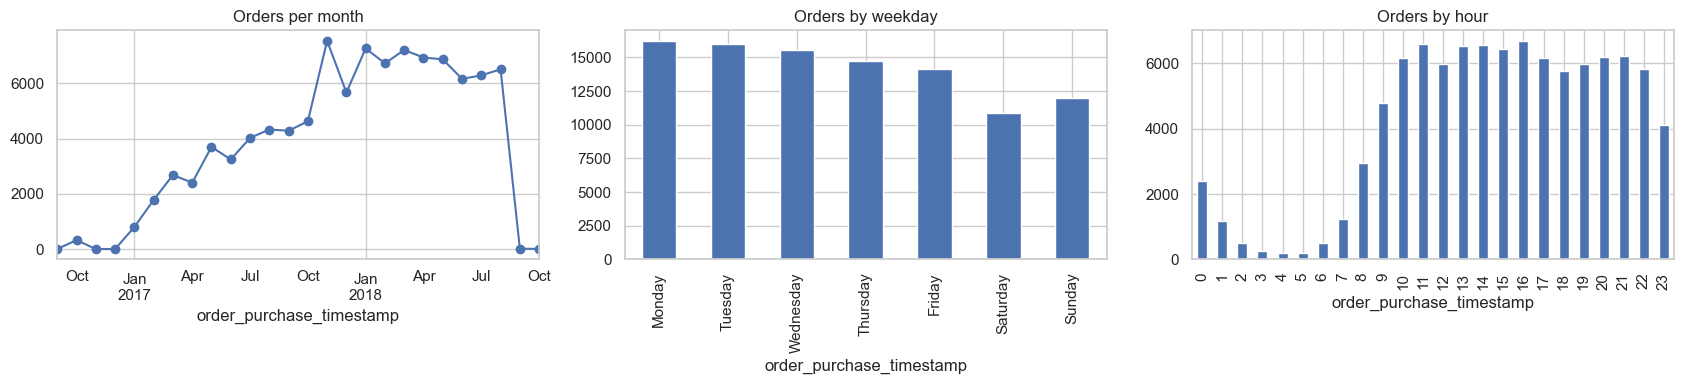

order_status,delivered,shipped,canceled,unavailable,invoiced,processing,created,approved
count,96478,1107,625,609,314,301,5,2


In [7]:
monthly = orders.set_index('order_purchase_timestamp').resample('ME').size()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
monthly.plot(ax=ax[0], marker='o', title='Orders per month')
orders.order_purchase_timestamp.dt.day_name().value_counts().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot.bar(ax=ax[1], title='Orders by weekday')
orders.order_purchase_timestamp.dt.hour.value_counts().sort_index().plot.bar(ax=ax[2], title='Orders by hour')
plt.tight_layout(); plt.show()
orders.order_status.value_counts().to_frame().T

- Orders grew fast through 2017 and leveled off at about 6,000 to 7,000 a month in 2018.
- The peak in Nov 2017 (7,544 orders) is probably because of seasonal sales or Black Friday.
- Sep to Dec 2016 and Sep to Oct 2018 have very few orders (as few as 1 in a month). These are partial periods at the edges of the data, not real drops, so they should be excluded from trend analysis.
- People buy most on weekdays (Monday is the highest) and during the day from 10:00 to 22:00. Very few orders come in between 02:00 and 06:00.
- 97% of orders are `delivered`. Canceled and unavailable orders together are about 1.2%.

### B2. Customers and geography

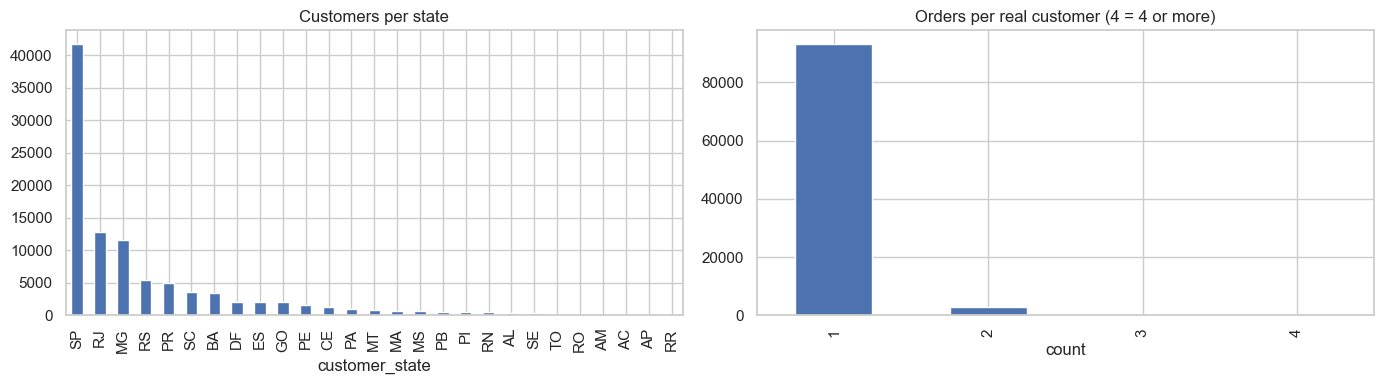

unique customers: 96096 | repeat buyers: 2997


In [8]:
customers = df['customers']
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
customers.customer_state.value_counts().plot.bar(ax=ax[0], title='Customers per state')
customers.customer_unique_id.value_counts().clip(upper=4).value_counts().sort_index().plot.bar(
    ax=ax[1], title='Orders per real customer (4 = 4 or more)')
plt.tight_layout(); plt.show()
print('unique customers:', customers.customer_unique_id.nunique(), '| repeat buyers:', (customers.customer_unique_id.value_counts() > 1).sum())


- Customers are concentrated in the southeast. SP alone has 42%, then RJ (13%) and MG (12%). The north has very few customers.
- 97% of real customers (`customer_unique_id`) buy only once. Only 2,997 bought again. Olist mostly gets new customers and rarely keeps them.

### B3. Products and categories

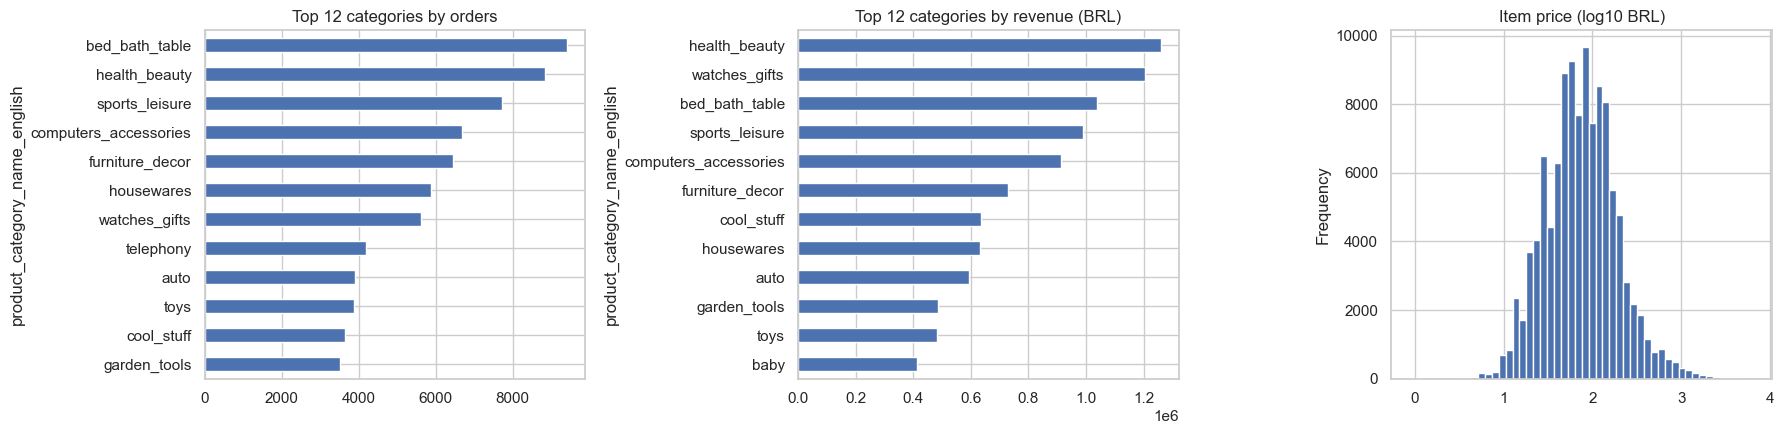

,price,freight_value,product_weight_g
count,112650.0,112650.0,112632.0
mean,120.7,20.0,2093.7
std,183.6,15.8,3751.6
min,0.8,0.0,0.0
25%,39.9,13.1,300.0
50%,75.0,16.3,700.0
75%,134.9,21.2,1800.0
max,6735.0,409.7,40425.0


In [9]:
items_products = df['items'].merge(df['products'], on='product_id', how='left').merge(df['translation'], on='product_category_name', how='left')
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
items_products.groupby('product_category_name_english').order_id.nunique().nlargest(12).sort_values().plot.barh(ax=ax[0], title='Top 12 categories by orders')
items_products.groupby('product_category_name_english').price.sum().nlargest(12).sort_values().plot.barh(ax=ax[1], title='Top 12 categories by revenue (BRL)')
np.log10(items_products.price).plot.hist(bins=50, ax=ax[2], title='Item price (log10 BRL)')
plt.tight_layout(); plt.show()
items_products[['price', 'freight_value', 'product_weight_g']].describe().round(1)

- `bed_bath_table` sells the most often, but `health_beauty` and `watches_gifts` make the most money, because watches cost more. Ranking by orders and ranking by revenue give different answers.
- Prices are **strongly right-skewed**:  median 75 BRL, mean 121 BRL, maximum 6,735 BRL. The log scale shows a roughly normal shape, so a log transform helps for modeling.
- Freight is on average about 20 BRL and is a big part of the cost for cheap items.

### B4. Sellers

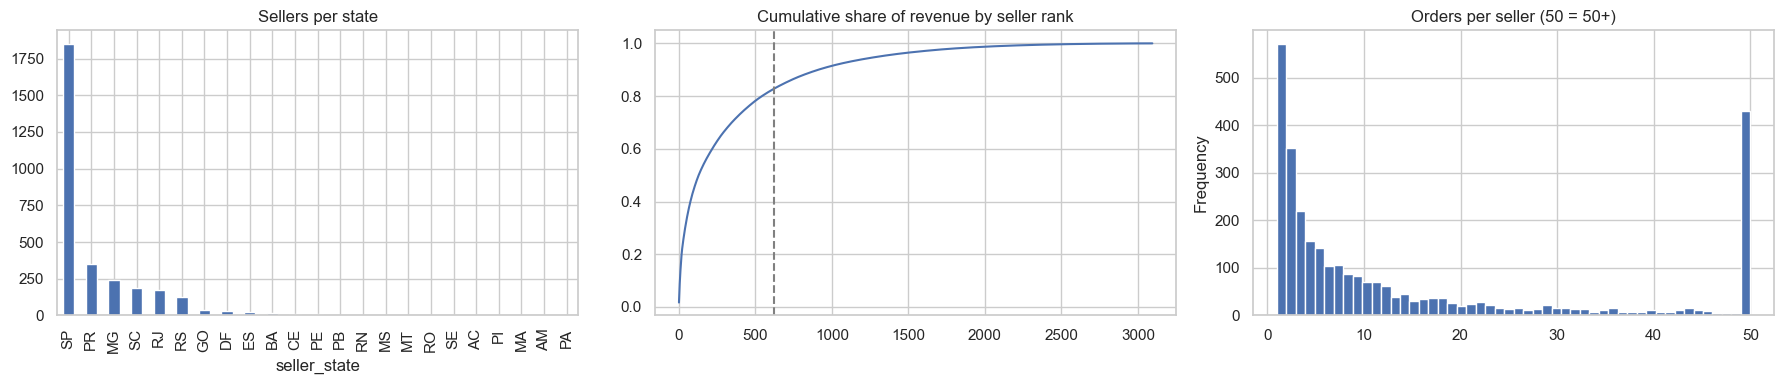

Top 20% of sellers make 83% of revenue


In [10]:
seller_revenue = df['items'].groupby('seller_id').price.sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
df['sellers'].seller_state.value_counts().plot.bar(ax=ax[0], title='Sellers per state')
(seller_revenue.cumsum() / seller_revenue.sum()).reset_index(drop=True).plot(ax=ax[1], title='Cumulative share of revenue by seller rank')
ax[1].axvline(len(seller_revenue) * .2, ls='--', c='grey')
df['items'].groupby('seller_id').order_id.nunique().clip(upper=50).plot.hist(bins=50, ax=ax[2], title='Orders per seller (50 = 50+)')
plt.tight_layout(); plt.show()
print(f'Top 20% of sellers make {seller_revenue.head(int(len(seller_revenue)*.2)).sum()/seller_revenue.sum():.0%} of revenue')

- 60% of sellers are in SP, which is even more concentrated than customers. Most products ship out of SP.
- The top 20% of sellers make 83% of the revenue. There are many very small sellers: 1,301 of 3,095 have fewer than 5 orders.

### B5. Payments

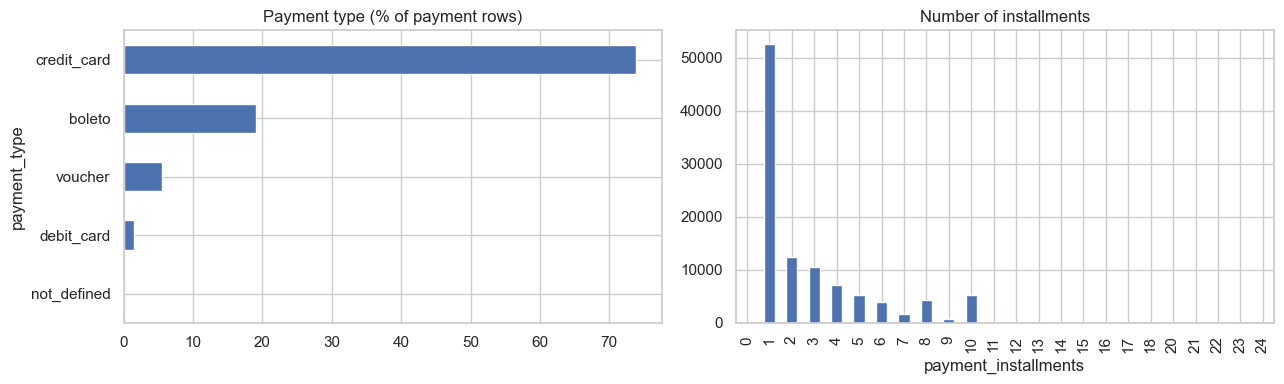

In [11]:
payments = df['payments']
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(payments.payment_type.value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax[0], title='Payment type (% of payment rows)')
payments.payment_installments.value_counts().sort_index().plot.bar(ax=ax[1], title='Number of installments')
plt.tight_layout(); plt.show()

- Credit card makes up 74% of payment rows, followed by boleto (a Brazilian bank slip, 19%) and vouchers (6%).
- Half of payments are in a single installment, but splitting into 2 to 10 installments is common in Brazil. Vouchers have the smallest amounts (66 BRL on average), because customers often combine several of them.

### B6. Delivery

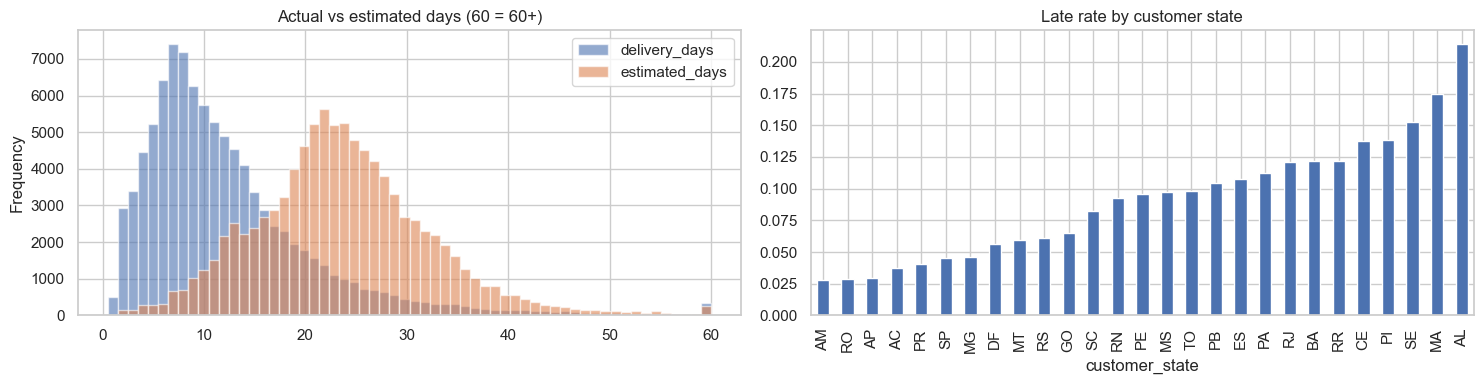

late: 6.8% | median delivery 10 days | median estimate 23 days


In [12]:
delivered = orders[orders.order_delivered_customer_date.notna()].copy()
delivered['delivery_days'] = (delivered.order_delivered_customer_date - delivered.order_purchase_timestamp).dt.total_seconds() / 86400
delivered['estimated_days'] = (delivered.order_estimated_delivery_date - delivered.order_purchase_timestamp).dt.total_seconds() / 86400
delivered['is_late'] = delivered.order_delivered_customer_date.dt.normalize() > delivered.order_estimated_delivery_date  # same day = on time
delivered = delivered.merge(customers[['customer_id', 'customer_state']])
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
delivered[['delivery_days', 'estimated_days']].clip(upper=60).plot.hist(bins=60, alpha=.6, ax=ax[0], title='Actual vs estimated days (60 = 60+)')
delivered.groupby('customer_state').is_late.mean().sort_values().plot.bar(ax=ax[1], title='Late rate by customer state')
plt.tight_layout(); plt.show()
print(f"late: {delivered.is_late.mean():.1%} | median delivery {delivered.delivery_days.median():.0f} days | median estimate {delivered.estimated_days.median():.0f} days")

- The median delivery takes 10 days, but Olist's median estimate is 23 days. Estimates are very cautious, so only 6.8% of orders arrive late. An order is late only if it arrives after the estimated day (the estimate has no time, so delivery on that day is on time).
- The late rate depends heavily on the state. It's 3% in AM but 21% in AL, and the northeast (AL, MA, PI) is worst. Distance and region will be important features for Task 5.
- Delivery days have a long tail (up to 209 days). Those orders are candidates for Task 4.

### B7. Reviews

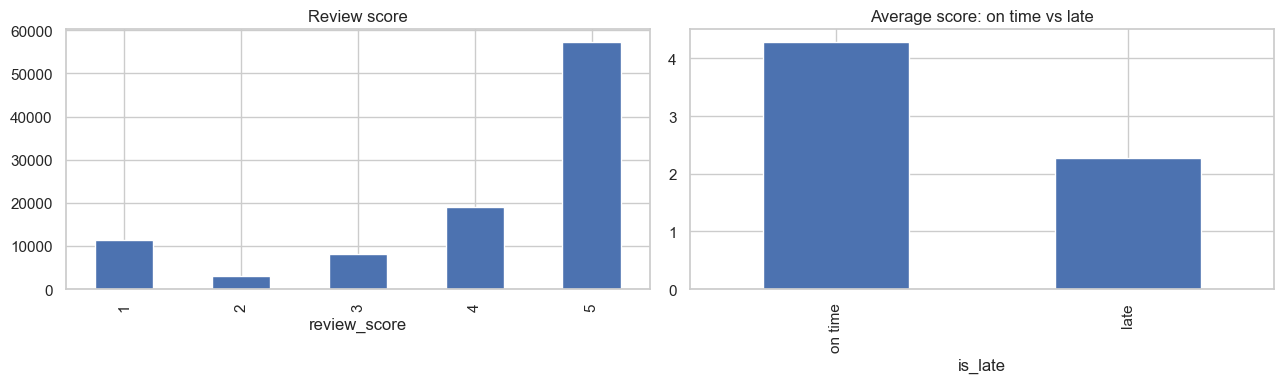

,avg score,share 1-2 stars
is_late,,
False,4.29,0.09
True,2.27,0.62


In [13]:
reviews_late = reviews.merge(delivered[['order_id', 'is_late']])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
reviews.review_score.value_counts().sort_index().plot.bar(ax=ax[0], title='Review score')
reviews_late.groupby('is_late').review_score.mean().rename({False: 'on time', True: 'late'}).plot.bar(ax=ax[1], title='Average score: on time vs late')
plt.tight_layout(); plt.show()
reviews_late.groupby('is_late').review_score.agg(['mean', lambda s: (s <= 2).mean()]).set_axis(['avg score', 'share 1-2 stars'], axis=1).round(2)

- Most scores are high (58% are 5 stars), but there's a noticeable group of 1-star reviews (11.5%).
- Lateness is linked to bad reviews. On-time orders average 4.3 stars, while late orders average 2.3. 62% of late orders get 1 or 2 stars, compared with 9% of on-time orders. Predicting lateness (Task 5) therefore matters directly for customer satisfaction.

### B8. Baskets 

In [14]:
cats = items_products.groupby('order_id').product_category_name.nunique()
print('orders with items:', len(cats), '| 2+ items:', (df['items'].order_id.value_counts() > 1).sum(), '| 2+ categories:', (cats > 1).sum())

orders with items: 98666 | 2+ items: 9803 | 2+ categories: 727


**Comment.** About 10% of orders contain 2 or more items, but most of those are multiple units of the same product. **Only 727 orders (0.7%) contain 2 or more categories.** Association rules based only on single orders will therefore be weak. For Task 2 we'll also build customer-level baskets, which combine all of a person's orders.

## C. Data quality checks

In [15]:
paid_per_order = payments.groupby('order_id').payment_value.sum()
items_total_per_order = df['items'].assign(t=lambda d: d.price + d.freight_value).groupby('order_id').t.sum()
checks = {
 'carrier pickup before approval': (orders.order_delivered_carrier_date < orders.order_approved_at).sum(),
 'delivered before carrier pickup': (orders.order_delivered_customer_date < orders.order_delivered_carrier_date).sum(),
 "status 'delivered' but no delivery date": ((orders.order_status == 'delivered') & orders.order_delivered_customer_date.isna()).sum(),
 "status 'canceled' but has delivery date": ((orders.order_status == 'canceled') & orders.order_delivered_customer_date.notna()).sum(),
 'orders with no items': (~orders.order_id.isin(df['items'].order_id)).sum(),
 'paid differs from items + freight (>1 BRL)': ((paid_per_order - items_total_per_order).abs() > 1).sum(),
 'payments of 0 / type not_defined': f"{(payments.payment_value == 0).sum()} / {(payments.payment_type == 'not_defined').sum()}",
 'orders with 2+ reviews': (reviews.order_id.value_counts() > 1).sum(),
 'products with no category': df['products'].product_category_name.isna().sum(),
 'categories missing English name': len(set(df['products'].product_category_name.dropna()) - set(df['translation'].product_category_name)),
 'products with weight 0': (df['products'].product_weight_g == 0).sum(),
 'items with freight 0': (df['items'].freight_value == 0).sum(),
}
pd.Series(checks, name='count').to_frame()

,count
carrier pickup before approval,1359
delivered before carrier pickup,23
status 'delivered' but no delivery date,8
status 'canceled' but has delivery date,6
orders with no items,775
paid differs from items + freight (>1 BRL),249
payments of 0 / type not_defined,9 / 3
orders with 2+ reviews,547
products with no category,610
categories missing English name,2


In [16]:
df['sellers'].seller_city[df['sellers'].seller_city.str.contains(r'[/\\@\d]')].unique()[:8]

<ArrowStringArray>
[         'auriflama/sp', 'sao paulo / sao paulo',              '04482255',
        'cariacica / es',                'sbc/sp', 'santo andre/sao paulo',
               'sp / sp',        'maua/sao paulo']
Length: 8, dtype: str

In [17]:
geo = df['geo']
outside = ~geo.geolocation_lat.between(-33.75, 5.27) | ~geo.geolocation_lng.between(-73.99, -32.0)
print('geo rows:', len(geo), '| zip prefixes:', geo.geolocation_zip_code_prefix.nunique(), '| points outside Brazil:', outside.sum())
geo[outside].head(8)

geo rows: 1000163 | zip prefixes: 19015 | points outside Brazil: 31


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES


**Issues observed**
- **Impossible date sequences** (1,359 picked up before approval, 23 delivered before pickup) are most likely recording errors. They're flagged, not deleted.
- **Status and date conflicts:** for example, "delivered" orders with no delivery date. 
- **Payment mismatches** (249 orders) can be interest on installments or errors.
- **Duplicate reviews:** 547 orders have 2 or more reviews.
- **Seller city text is messy** (`sao paulo / sao paulo`, `sbc/sp`, even a zip code) and 31 geolocation points lie outside Brazil** (Portugal, Spain, USA, Philippines and others)

## D. Data preparation
### D1. Fix geolocation
Rule used: Replaced the coordinates of each point outside Brazil with **the most common coordinates of good points that have the same city and state**. If a city has no good points, its coordinates are left empty, and the zip later takes the **nearest zip prefix in the same state** (Brazilian zip codes are given out by area, so neighboring numbers are physically close). Then reduce the table to **one row per zip prefix** using the median.


In [18]:
norm = lambda s: s.map({v: unicodedata.normalize('NFKD', str(v)).encode('ascii', 'ignore').decode().lower().strip() for v in s.unique()})
geo['key'] = norm(geo.geolocation_city) + '|' + geo.geolocation_state
city_mode = (geo[~outside].groupby(['key', 'geolocation_lat', 'geolocation_lng']).size().reset_index()
        .sort_values(0).drop_duplicates('key', keep='last').set_index('key'))
geo.loc[outside, 'geolocation_lat'] = geo.loc[outside, 'key'].map(city_mode.geolocation_lat)
geo.loc[outside, 'geolocation_lng'] = geo.loc[outside, 'key'].map(city_mode.geolocation_lng)
print('fixed by city/state:', geo.loc[outside, 'geolocation_lat'].notna().sum(), '| no match (left empty):', geo.loc[outside, 'geolocation_lat'].isna().sum())

geo_zip = (geo.dropna(subset=['geolocation_lat'])
           .groupby('geolocation_zip_code_prefix')
           .agg(lat=('geolocation_lat', 'median'), lng=('geolocation_lng', 'median'), state=('geolocation_state', lambda s: s.mode()[0]))
           .reset_index().rename(columns={'geolocation_zip_code_prefix': 'zip'}).sort_values('zip'))

def add_geo(d, zip_col, state_col):
    # exact zip match, otherwise the nearest zip prefix in the same state
    left = d[[zip_col, state_col]].drop_duplicates().rename(columns={zip_col: 'zip', state_col: 'state'}).sort_values('zip')
    m = pd.merge_asof(left, geo_zip, on='zip', by='state', direction='nearest')
    return d.merge(m.rename(columns={'zip': zip_col, 'state': state_col}), on=[zip_col, state_col], how='left')

customers = add_geo(df['customers'], 'customer_zip_code_prefix', 'customer_state')
sellers = add_geo(df['sellers'], 'seller_zip_code_prefix', 'seller_state')
print('zip prefixes:', len(geo_zip), '| customers without coordinates:', customers.lat.isna().sum(), '| sellers:', sellers.lat.isna().sum())

fixed by city/state: 26 | no match (left empty): 5
zip prefixes: 19012 | customers without coordinates: 0 | sellers: 0


**Result.** 26 bad points were fixed using their city and state. 5 points (bom retiro da esperanca, pau d'arco, ilha dos valadares, santa lucia do piai) had no match, so their zips get the nearest prefix in the same state. The geolocation table is reduced from 1M rows to 19,012 zip prefixes, and **every customer and seller now has coordinates**, including the ~285 whose zip wasn't in the geolocation file.

### D2. Orders: flags and new features
- **Kept all orders.** Add `is_delivered` and `is_canceled` so each task can filter what it needs.
- **Time features** (`delivery_days`, `estimated_days`, `is_late`, `days_late`, `approval_hours`, `carrier_days`).
- **Data quality flags.** 
- **`partial_month`** for months with fewer than 500 orders. 

In [19]:
days = lambda a, b: (orders[a] - orders[b]).dt.total_seconds() / 86400
orders['is_delivered'] = orders.order_status.eq('delivered') & orders.order_delivered_customer_date.notna()
orders['is_canceled'] = orders.order_status.isin(['canceled', 'unavailable'])
orders['delivery_days'] = days('order_delivered_customer_date', 'order_purchase_timestamp')
orders['estimated_days'] = days('order_estimated_delivery_date', 'order_purchase_timestamp')
orders['days_late'] = (orders.order_delivered_customer_date.dt.normalize() - orders.order_estimated_delivery_date).dt.days  # 0 = arrived on the due day
orders['is_late'] = (orders.days_late > 0).astype(float).where(orders.order_delivered_customer_date.notna())
orders['approval_hours'] = days('order_approved_at', 'order_purchase_timestamp') * 24
orders['carrier_days'] = days('order_delivered_carrier_date', 'order_approved_at')
orders['purchase_month'] = orders.order_purchase_timestamp.dt.to_period('M').astype(str)
orders['purchase_weekday'] = orders.order_purchase_timestamp.dt.dayofweek
orders['purchase_hour'] = orders.order_purchase_timestamp.dt.hour
orders['partial_month'] = orders.purchase_month.map(orders.purchase_month.value_counts() < 500)
orders['flag_carrier_before_approval'] = orders.order_delivered_carrier_date < orders.order_approved_at
orders['flag_delivered_before_carrier'] = orders.order_delivered_customer_date < orders.order_delivered_carrier_date
orders['flag_status_conflict'] = ((orders.order_status == 'delivered') & orders[date_steps].isna().any(axis=1)) | \
                            ((orders.order_status == 'canceled') & orders.order_delivered_customer_date.notna())
orders.filter(like='flag_').sum()

flag_carrier_before_approval     1359
flag_delivered_before_carrier      23
flag_status_conflict               29
dtype: int64

### D3. Products
- Missing category → `unknown`. *Why:* the products were still sold, so dropping them would lose sales.
- Add the 2 missing English translations by hand because 2 are few and its possible.
- Add `volume_cm3`. *Why:* size drives freight cost and delivery time.
- Weight 0 → missing. *Why:* a real product can't weigh 0 g.

In [20]:
translation = pd.concat([df['translation'], pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers', 'unknown']})])
products = df['products'].fillna({'product_category_name': 'unknown'}).merge(translation, how='left')
products['product_weight_g'] = products.product_weight_g.replace(0, np.nan)
products['volume_cm3'] = products.product_length_cm * products.product_height_cm * products.product_width_cm
products = products.rename(columns={'product_category_name_english': 'category'})
print('missing category after fix:', products.category.isna().sum())

missing category after fix: 0


### D4. Payments → one row per order
*Why:* an order can have up to 29 payment rows. Joining them directly would duplicate the order rows and inflate totals.

In [21]:
payments_per_order = payments.groupby('order_id').agg(total_paid=('payment_value', 'sum'), n_payments=('payment_value', 'size'),
                                    max_installments=('payment_installments', 'max'),
                                    used_voucher=('payment_type', lambda s: s.eq('voucher').any()))
payments_per_order['main_payment_type'] = payments.sort_values('payment_value').drop_duplicates('order_id', keep='last').set_index('order_id').payment_type
payments_per_order.head(3)

,total_paid,n_payments,max_installments,used_voucher,main_payment_type
order_id,,,,,
00010242fe8c5a6d1ba2dd792cb16214,72.19,1,2,False,credit_card
00018f77f2f0320c557190d7a144bdd3,259.83,1,3,False,credit_card
000229ec398224ef6ca0657da4fc703e,216.87,1,5,False,credit_card


### D5. Reviews → latest review per order
547 orders have more than one review, so i took the latest one is the customer' final submission.

In [22]:
reviews_per_order = reviews.sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last')
reviews_per_order = reviews_per_order.assign(has_comment=reviews_per_order.review_comment_message.notna())[['order_id', 'review_score', 'has_comment', 'review_creation_date']]
print(len(reviews), '->', len(reviews_per_order))

99224 -> 98673


### D6. Sellers: clean city text
 the same city is written in several ways (`sao paulo / sao paulo`, `sbc/sp`),therefore these were merged.

In [23]:
sellers['seller_city'] = norm(sellers.seller_city.str.split(r'[/\\,]').str[0])
bad_city = sellers.seller_city.str.contains(r'\d|@') | sellers.seller_city.eq(sellers.seller_state.str.lower())
sellers.loc[bad_city, 'seller_city'] = np.nan   # zip codes, emails or a state code typed as a city
print('cities:', df['sellers'].seller_city.nunique(), 'become', sellers.seller_city.nunique())

cities: 611 become 589


### D7. Items: add product, seller and distance
**Distance** (haversine, in km) between seller and customer. *Why:* distance is expected to be one of the strongest drivers of delivery time 

In [24]:
def haversine(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

items = (df['items']
         .merge(products[['product_id', 'category', 'product_weight_g', 'volume_cm3']], on='product_id', how='left')
         .merge(sellers.rename(columns={'lat': 's_lat', 'lng': 's_lng'}), on='seller_id', how='left')
         .merge(orders[['order_id', 'customer_id']], on='order_id')
         .merge(customers.rename(columns={'lat': 'c_lat', 'lng': 'c_lng'}), on='customer_id', how='left'))
items['distance_km'] = haversine(items.s_lat, items.s_lng, items.c_lat, items.c_lng)
items.distance_km.describe().round(0)

count    112650.0
mean        598.0
std         589.0
min           0.0
25%         186.0
50%         433.0
75%         794.0
max        3579.0
Name: distance_km, dtype: float64

### D8. Outliers: flag using the IQR rule (above Q3 + 1.5 × IQR). 

In [25]:
iqr_flag = lambda s: s > s.quantile(.75) + 1.5 * (s.quantile(.75) - s.quantile(.25))
items['out_price'] = iqr_flag(items.price)
items['out_freight'] = iqr_flag(items.freight_value)
orders['out_delivery_days'] = iqr_flag(orders.delivery_days)
print(items[['out_price', 'out_freight']].sum().to_dict(), '| delivery:', orders.out_delivery_days.sum())

{'out_price': 8427, 'out_freight': 11613} | delivery: 4899


## E. Final tables
### E1. `orders_master`: one row per order

In [26]:
items_per_order = items.groupby('order_id').agg(n_items=('order_item_id', 'size'), n_sellers=('seller_id', 'nunique'),
    n_categories=('category', 'nunique'), items_value=('price', 'sum'), freight_value=('freight_value', 'sum'),
    weight_g=('product_weight_g', 'sum'), volume_cm3=('volume_cm3', 'sum'), distance_km=('distance_km', 'mean'),
    any_out_price=('out_price', 'any'))
size_missing = items.assign(w=items.product_weight_g.isna(), v=items.volume_cm3.isna()).groupby('order_id')[['w', 'v']].any()
items_per_order.loc[size_missing.w, 'weight_g'] = np.nan     # don't let a missing weight count as 0
items_per_order.loc[size_missing.v, 'volume_cm3'] = np.nan
orders_master = (orders.merge(customers[['customer_id', 'customer_unique_id', 'customer_state', 'lat', 'lng']], on='customer_id', how='left')
       .merge(items_per_order, on='order_id', how='left').merge(payments_per_order, on='order_id', how='left').merge(reviews_per_order, on='order_id', how='left'))
orders_master['freight_ratio'] = orders_master.freight_value / orders_master.items_value
orders_master['flag_payment_mismatch'] = (orders_master.total_paid - orders_master.items_value - orders_master.freight_value).abs() > 1
orders_master['flag_no_items'] = orders_master.n_items.isna()
orders_master['flag_review_before_purchase'] = orders_master.review_creation_date < orders_master.order_purchase_timestamp.dt.normalize()
print(orders_master.shape); orders_master.filter(like='flag_').sum()

(99441, 49)


flag_carrier_before_approval     1359
flag_delivered_before_carrier      23
flag_status_conflict               29
flag_payment_mismatch             250
flag_no_items                     775
flag_review_before_purchase        61
dtype: int64

### E2. `seller_profile`: one row per seller

In [27]:
seller_items = items.merge(orders_master[['order_id', 'is_canceled', 'is_late', 'delivery_days', 'review_score', 'order_purchase_timestamp']], on='order_id')
seller_items['sold_value'] = seller_items.price.where(~seller_items.is_canceled, 0)   # canceled items are not revenue

# sales measures: one row per item
item_level = seller_items.groupby('seller_id').agg(
    n_orders=('order_id', 'nunique'), n_items=('order_item_id', 'size'), revenue=('sold_value', 'sum'),
    avg_price=('price', 'mean'), avg_freight=('freight_value', 'mean'), n_categories=('category', 'nunique'),
    avg_distance_km=('distance_km', 'mean'))

# service measures: count each order once per seller, so big orders don't count many times
order_level = seller_items.drop_duplicates(['seller_id', 'order_id']).groupby('seller_id').agg(
    avg_review=('review_score', 'mean'), late_rate=('is_late', 'mean'), cancel_rate=('is_canceled', 'mean'),
    avg_delivery_days=('delivery_days', 'mean'),
    first_sale=('order_purchase_timestamp', 'min'), last_sale=('order_purchase_timestamp', 'max'))

seller_profile = item_level.join(order_level)
seller_profile['active_months'] = ((seller_profile.last_sale - seller_profile.first_sale).dt.days / 30).round(1)
seller_profile = sellers[['seller_id', 'seller_city', 'seller_state']].merge(seller_profile.reset_index(), on='seller_id', how='left')
seller_profile.describe().T.round(1)

,count,mean,min,25%,50%,75%,max,std
n_orders,3095.0,32.313409,1.0,2.0,6.0,21.5,1854.0,105.139763
n_items,3095.0,36.397415,1.0,2.0,8.0,24.0,2033.0,119.193461
revenue,3095.0,4360.064859,0.0,199.985,799.5,3265.2,229237.63,13877.558183
avg_price,3095.0,176.325102,3.5,52.183608,95.465385,173.992857,6729.0,322.145495
avg_freight,3095.0,23.380116,1.2,14.74,18.23,24.368333,308.336667,18.957766
n_categories,3095.0,2.137641,1.0,1.0,1.0,2.0,27.0,2.116009
avg_distance_km,3095.0,613.777305,1.135905,377.319206,550.154361,759.795456,2798.84369,395.241938
avg_review,3090.0,3.998067,1.0,3.777778,4.184413,4.6,5.0,0.957323
late_rate,2970.0,0.069093,0.0,0.0,0.0,0.076923,1.0,0.156269
cancel_rate,3095.0,0.024679,0.0,0.0,0.0,0.0,1.0,0.128932


### E3. `basket_items`: order and customer baskets

In [28]:
basket = items[['order_id', 'category']].drop_duplicates().merge(orders_master[['order_id', 'customer_unique_id']], on='order_id')
print('order baskets with 2+ categories:', (basket.groupby('order_id').size() > 1).sum(),
      '| customer baskets with 2+ categories:', (basket.groupby('customer_unique_id').category.nunique() > 1).sum())

order baskets with 2+ categories: 786 | customer baskets with 2+ categories: 2327


**Note: ** This is one row per order and category. The counts are a bit higher than in B8 (727) because `unknown` now counts as a category. Customer baskets give about 3 times more multi-category baskets than single orders.

### E4. Check after preparation: relationships between variables

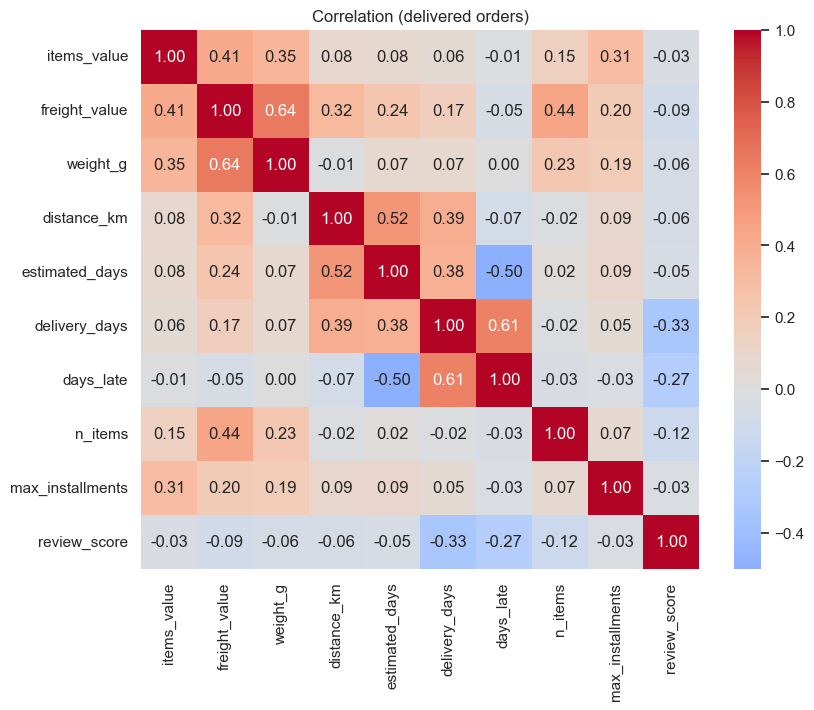

In [29]:
numeric = orders_master.loc[orders_master.is_delivered, ['items_value', 'freight_value', 'weight_g', 'distance_km', 'estimated_days',
                               'delivery_days', 'days_late', 'n_items', 'max_installments', 'review_score']]
plt.figure(figsize=(9, 7)); sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0); plt.title('Correlation (delivered orders)'); plt.show()


- `distance_km` is linked to `estimated_days` (0.52), `delivery_days` (0.39) and `freight_value` (0.32).
- `review_score` drops as `delivery_days` (-0.33) and `days_late` (-0.27) increase, and it's almost unrelated to price (-0.03).
- `weight_g` is the main driver of freight cost (0.64).
- `estimated_days` vs `days_late` (-0.50): longer estimates mean fewer late orders, so Olist uses padded estimates to avoid lateness.

### E5. Save

In [30]:
import os; os.makedirs('clean', exist_ok=True)
for name, t in {'orders_master': orders_master, 'order_items_clean': items, 'seller_profile': seller_profile,
                'basket_items': basket, 'geolocation_by_zip': geo_zip}.items():
    t.to_csv(f'clean/{name}.csv', index=False); print(f'{name:20s}', t.shape)

orders_master        (99441, 49)
order_items_clean    (112650, 25)
seller_profile       (3095, 17)
basket_items         (99470, 3)
geolocation_by_zip   (19012, 4)


## Summary of preparation decisions

| Problem | Action | Justification |
|---|---|---|
| 31 geo points outside Brazil | 26 replaced with most common city/state coordinates, 5 left to nearest zip | Keeps every customer on the map for distance analysis|
| 1M geo rows for 19k zips | Median per zip prefix | Clean 1-to-1 join, no row explosion |
| ~285 customers/sellers with no zip in geo, plus 5 bad points with no city match | Nearest zip prefix in same state | Zip codes are assigned by area |
| Late measured by timestamp (1,292 same-day deliveries looked late) | Late = arrived after the estimated day | The estimate is a date with no time |
| Non-delivered orders | Kept + `is_delivered`, `is_canceled` | Each task filters what it needs |
| Impossible dates, status conflicts, payment mismatch | Flagged|useful metric for analysis|
| Partial months (2016, Sep–Oct 2018) | `partial_month` flag | Avoid false trend drops |
| Multiple payments per order | Aggregated per order | Avoid double counting |
| Multiple reviews per order | Kept latest | Assumed final opinion of customer |
| 610 products without category | `unknown` | Keep the sales |
| 2 untranslated categories | Translated by hand | Complete English names |
| Weight 0 | Set to missing | Impossible value |
| Messy seller city text | Cleaned and normalized | useful metric for analysis |
| Price, freight, delivery outliers | IQR flags, not removed | useful metric for analysis |

# Task 2. Product categories bought together


The two perspectives considered:
- **Order basket:** categories inside the same order. This is the strict meaning.
- **Customer basket:** all categories one person (`customer_unique_id`) bought across all their orders. This also picks up "bought later" behaviour, which matters for cross-selling.

**Assumptions**
- I work at **category level**, not product level. There are almost 33,000 products, and most of them sold only a handful of times, which is too sparse for rules.
- I drop the `unknown` category, because a rule like "unknown → toys" can't be acted on.
- I only look at **pairs** of categories. As the table below shows, baskets with 3 or more categories are very rare.

In [31]:
from itertools import combinations
from collections import Counter
from scipy.stats import fisher_exact, false_discovery_control

# drop 'unknown', it is not a real category, so a rule with it can't be acted on
bask = basket[basket.category != 'unknown'].copy()
bask = bask.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id')

# how many categories does a basket have?
cats_per_order = bask.groupby('order_id').category.nunique()
cats_per_customer = bask.groupby('customer_unique_id').category.nunique()
pd.DataFrame({'orders': cats_per_order.value_counts().sort_index(),
              'customers': cats_per_customer.value_counts().sort_index()}).head(5)

,orders,customers
category,,
1,96550.0,91896
2,712.0,2084
3,15.0,111
4,NaN,12
5,NaN,5


Out of 97,277 orders (excluding `unknown`), only **727 (0.75%) contain 2 or more categories**. At customer level it's 2,212 of 94,108 people (2.4%). Only 15 orders have 3 categories, so working with pairs will do.

In [32]:
# orders with 2+ items: are the items from the same category or even the same product?
multi = items[items.order_id.isin(items.order_id.value_counts().loc[lambda s: s > 1].index)]
per_order = multi.groupby('order_id').agg(n_products=('product_id', 'nunique'), n_cats=('category', 'nunique'))
print('orders with 2+ items:', len(per_order))
print('same product repeated :', (per_order.n_products == 1).mean().round(3))
print('one category, different products:', ((per_order.n_products > 1) & (per_order.n_cats == 1)).mean().round(3))
print('2+ categories          :', (per_order.n_cats > 1).mean().round(3))

orders with 2+ items: 9803
same product repeated : 0.67
one category, different products: 0.25
2+ categories          : 0.08


Of the 9,803 orders with more than one item, **67% are the same product bought several times**, 25% are different products from the same category, and only **8% mix categories**. At Olist, "bought together" mostly means "more of the same". I come back to this in the recommendations.

### 2.1 Method
I use **association rules** (Agrawal, Imieliński & Swami, 1993) on category pairs. For a pair A and B:

| Measure | Meaning | Formula |
|---|---|---|
| support | share of baskets with both A and B | n(A and B) / n |
| confidence A → B | of baskets with A, share that also have B | n(A and B) / n(A) |
| lift | how much more often A and B appear together than if they were independent | n(A and B) × n / (n(A) × n(B)) |

Lift above 1 means the pair goes together more than chance (Brin et al., 1997). Lift alone can be high just by luck when counts are small, so for each pair I also run:
- a **one-sided Fisher exact test** on the 2×2 table (with A / without A × with B / without B), and
- a **Benjamini-Hochberg correction** (Benjamini & Hochberg, 1995), because hundreds of pairs are tested at once and some would look significant by chance.

A pair counts as a rule only if it was seen **at least 10 times**, has **lift > 1**, and has **adjusted p < 0.05**. Why 10: with fewer baskets a single customer moves the lift a lot, and the Fisher test has almost no power to confirm the pair. The sensitivity check in 2.4 shows what happens with 5, 20 and 30.

In [33]:
def pair_rules(data, level):
    """Support, confidence and lift for every pair of categories bought by the same basket.
    level = 'order_id' (one order) or 'customer_unique_id' (all orders of one person)."""
    baskets = data.groupby(level).category.apply(set)
    n = len(baskets)
    cat_count = data.drop_duplicates([level, 'category']).category.value_counts()
    pair_count = Counter(p for b in baskets if len(b) > 1 for p in combinations(sorted(b), 2))
    rows = []
    for (a, b), n_ab in pair_count.items():
        n_a, n_b = cat_count[a], cat_count[b]
        # 2x2 table: baskets with a and b, a only, b only, neither
        table = [[n_ab, n_a - n_ab], [n_b - n_ab, n - n_a - n_b + n_ab]]
        p = fisher_exact(table, alternative='greater').pvalue
        rows.append({'cat_a': a, 'cat_b': b, 'n_together': n_ab, 'support': n_ab / n,
                     'conf_a_to_b': n_ab / n_a, 'conf_b_to_a': n_ab / n_b,
                     'lift': n_ab * n / (n_a * n_b), 'p_value': p})
    rules = pd.DataFrame(rows)
    rules['p_adj'] = false_discovery_control(rules.p_value)  # Benjamini-Hochberg, many pairs are tested
    return rules.sort_values('n_together', ascending=False).reset_index(drop=True)

### 2.2 Baseline: all orders
First the usual way: every order is a basket, including the 99% with one category. This is my baseline.

In [34]:
rules_all = pair_rules(bask, 'order_id')
print('pairs found:', len(rules_all), '| pairs with lift > 1:', (rules_all.lift > 1).sum())
rules_all.head(8).round(4)

pairs found: 243 | pairs with lift > 1: 18


,cat_a,cat_b,n_together,support,conf_a_to_b,conf_b_to_a,lift,p_value,p_adj
0,bed_bath_table,furniture_decor,70,0.0007,0.0074,0.0109,0.1121,1.0000,1.0
1,bed_bath_table,home_confort,43,0.0004,0.0046,0.1083,1.1189,0.2408,1.0
2,furniture_decor,housewares,24,0.0002,0.0037,0.0041,0.0615,1.0000,1.0
3,baby,cool_stuff,20,0.0002,0.0069,0.0055,0.1857,1.0000,1.0
4,bed_bath_table,housewares,20,0.0002,0.0021,0.0034,0.0351,1.0000,1.0
5,baby,toys,19,0.0002,0.0066,0.0049,0.1649,1.0000,1.0
6,furniture_decor,garden_tools,17,0.0002,0.0026,0.0048,0.0729,1.0000,1.0
7,baby,bed_bath_table,17,0.0002,0.0059,0.0018,0.0609,1.0000,1.0


Over all orders, only 18 of 243 pairs have lift above 1, and **none is significant** (adjusted p = 1 for the common pairs). Even the most common pair, `bed_bath_table + furniture_decor` (70 orders), has a lift of 0.11, so the two appear together about 9 times *less* often than chance would predict.

The reason could mean that every order holds one category, so any mix of categories is rarer than independence expects. **Honest conclusion: on Olist, buying across categories in one order is not a common habit.** This is the main limitation of Task 2, and I state it clearly instead of hiding it.

### 2.3 Within cross-category baskets


In [35]:
MIN_COUNT = 10   # ignore pairs seen fewer than 10 times, too few to trust

def multi_cat(data, level):
    keep = data.groupby(level).category.nunique().loc[lambda s: s > 1].index
    return data[data[level].isin(keep)]

rules_order = pair_rules(multi_cat(bask, 'order_id'), 'order_id')
rules_cust = pair_rules(multi_cat(bask, 'customer_unique_id'), 'customer_unique_id')

show = ['cat_a', 'cat_b', 'n_together', 'conf_a_to_b', 'conf_b_to_a', 'lift', 'p_adj']
strong_cust = rules_cust[(rules_cust.n_together >= MIN_COUNT) & (rules_cust.lift > 1) & (rules_cust.p_adj < 0.05)]
print('customer level, pairs seen 10+ times:', (rules_cust.n_together >= MIN_COUNT).sum(), '| significant with lift > 1:', len(strong_cust))
strong_cust.sort_values('lift', ascending=False)[show].round(3)

customer level, pairs seen 10+ times: 67 | significant with lift > 1: 5


,cat_a,cat_b,n_together,conf_a_to_b,conf_b_to_a,lift,p_adj
3,bed_bath_table,home_confort,54,0.100,0.740,3.036,0.000
24,construction_tools_lights,furniture_decor,18,0.600,0.035,2.577,0.003
7,baby,cool_stuff,31,0.179,0.196,2.509,0.000
9,baby,toys,27,0.156,0.156,1.996,0.021
0,bed_bath_table,furniture_decor,156,0.289,0.303,1.243,0.021


In [36]:
strong_order = rules_order[(rules_order.n_together >= MIN_COUNT) & (rules_order.lift > 1) & (rules_order.p_adj < 0.05)]
print('order level, pairs seen 10+ times:', (rules_order.n_together >= MIN_COUNT).sum(), '| significant with lift > 1:', len(strong_order))
strong_order.sort_values('lift', ascending=False)[show].round(3)

order level, pairs seen 10+ times: 17 | significant with lift > 1: 4


,cat_a,cat_b,n_together,conf_a_to_b,conf_b_to_a,lift,p_adj
10,health_beauty,perfumery,12,0.171,0.462,4.793,0.000
1,bed_bath_table,home_confort,43,0.217,0.860,3.158,0.000
5,baby,toys,19,0.204,0.380,2.971,0.000
3,baby,cool_stuff,20,0.215,0.303,2.369,0.003


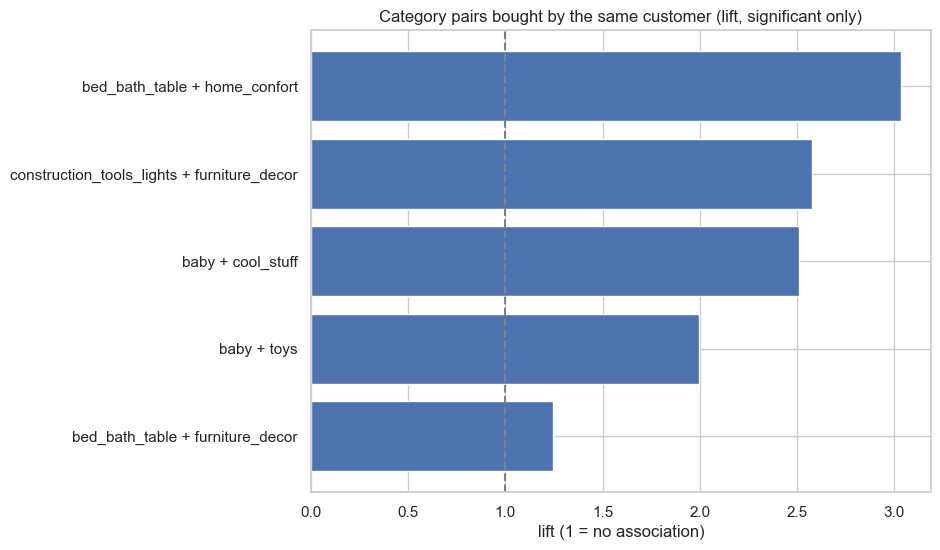

In [37]:
top = strong_cust.sort_values('lift').tail(15)
plt.figure(figsize=(8, 6))
plt.barh(top.cat_a + ' + ' + top.cat_b, top.lift)
plt.axvline(1, color='grey', ls='--')
plt.title('Category pairs bought by the same customer (lift, significant only)')
plt.xlabel('lift (1 = no association)'); plt.show()

**Customer level** (2,212 cross-category customers): 67 pairs were seen 10 or more times, and **5 are significant with lift > 1**.

**Order level** (727 orders): **4 significant pairs.**

The pairs fall into 3 clear themes:
- **Home comfort:** `bed_bath_table + home_confort` (lift about 3 at both levels). The direction matters. 74 to 86% of people who buy `home_confort` across categories also buy `bed_bath_table`, but only 10 to 22% go the other way. So the offer should go *to* home_confort buyers.
- **Baby and gifts:** `baby + toys` (lift 2.0 to 3.0) and `baby + cool_stuff` (lift 2.4 to 2.5).
- **Beauty:** `health_beauty + perfumery` (lift 4.8, but only 12 orders, so I treat it as a lead, not a fact).

`bed_bath_table + furniture_decor` is the most frequent pair (156 customers), but its lift is only 1.24, so it mostly reflects that both categories are popular.

### 2.4 Robustness checks
Three checks: (a) do the rules hold in both years, (b) do they survive a stricter minimum count, and (c) how precise is each lift?

In [38]:
# (a) do the pairs found in 2017 still show up in 2018?
y = bask.order_purchase_timestamp.dt.year
r17 = pair_rules(multi_cat(bask[y == 2017], 'customer_unique_id'), 'customer_unique_id')
r18 = pair_rules(multi_cat(bask[y == 2018], 'customer_unique_id'), 'customer_unique_id')
check = strong_cust[['cat_a', 'cat_b', 'n_together', 'lift']].merge(
    r17[['cat_a', 'cat_b', 'n_together', 'lift']], on=['cat_a', 'cat_b'], how='left', suffixes=('', '_2017')).merge(
    r18[['cat_a', 'cat_b', 'n_together', 'lift']].rename(columns={'n_together': 'n_together_2018', 'lift': 'lift_2018'}), on=['cat_a', 'cat_b'], how='left')
check['holds_both_years'] = (check.lift_2017 > 1) & (check.lift_2018 > 1)
print('significant pairs with lift > 1 in BOTH years:', check.holds_both_years.sum(), 'of', len(check))
check.sort_values('lift', ascending=False).round(2)

significant pairs with lift > 1 in BOTH years: 3 of 5


,cat_a,cat_b,n_together,lift,n_together_2017,lift_2017,n_together_2018,lift_2018,holds_both_years
1,bed_bath_table,home_confort,54,3.04,40.0,2.71,14,3.55,True
4,construction_tools_lights,furniture_decor,18,2.58,NaN,NaN,18,2.95,False
2,baby,cool_stuff,31,2.51,20.0,3.28,10,2.11,True
3,baby,toys,27,2.00,17.0,2.86,8,1.57,True
0,bed_bath_table,furniture_decor,156,1.24,99.0,1.49,44,0.98,False


In [39]:
# (b) how sensitive is the number of rules to the minimum count?
sens = []
for m in [5, 10, 20, 30]:
    for name, r in [('order', rules_order), ('customer', rules_cust)]:
        ok = (r.n_together >= m) & (r.lift > 1) & (r.p_adj < 0.05)
        sens.append({'min_count': m, 'level': name, 'rules': ok.sum()})
pd.DataFrame(sens).pivot(index='min_count', columns='level', values='rules')

level,customer,order
min_count,,
5,6,6
10,5,4
20,4,2
30,3,1


In [40]:
# (c) how precise is each lift? bootstrap the customers 500 times and take the 2.5% and 97.5% points
mc = multi_cat(bask, 'customer_unique_id')
onehot = pd.crosstab(mc.customer_unique_id, mc.category).gt(0).to_numpy()
cat_pos = {c: i for i, c in enumerate(pd.crosstab(mc.customer_unique_id, mc.category).columns)}
rng = np.random.default_rng(42)
boot = rng.integers(0, len(onehot), size=(500, len(onehot)))       # 500 resamples of the customers
ci = []
for _, r in strong_cust.iterrows():
    A, B = onehot[:, cat_pos[r.cat_a]], onehot[:, cat_pos[r.cat_b]]
    lifts = [(A[i] & B[i]).sum() * len(i) / (A[i].sum() * B[i].sum()) for i in boot]
    ci.append({'pair': r.cat_a + ' + ' + r.cat_b, 'lift': round(r.lift, 2),
               'ci_low': round(np.percentile(lifts, 2.5), 2), 'ci_high': round(np.percentile(lifts, 97.5), 2)})
pd.DataFrame(ci)

,pair,lift,ci_low,ci_high
0,bed_bath_table + furniture_decor,1.24,1.10,1.38
1,bed_bath_table + home_confort,3.04,2.62,3.46
2,baby + cool_stuff,2.51,1.86,3.27
3,baby + toys,2.00,1.34,2.72
4,construction_tools_lights + furniture_decor,2.58,1.84,3.31


- **Time:** 3 of the 5 customer-level rules have lift > 1 in **both 2017 and 2018**: `bed_bath_table + home_confort`, `baby + cool_stuff` and `baby + toys`. These are the ones I trust. `bed_bath_table + furniture_decor` falls to 0.98 in 2018, so it isn't stable. `construction_tools_lights + furniture_decor` only appears in 2018, so it's promising but not proven.
- **Minimum count:** raising the threshold from 5 to 30 reduces the customer-level rules from 6 to 3. The survivors at 30 are `bed_bath_table + home_confort`, `baby + cool_stuff` and `bed_bath_table + furniture_decor`. `baby + toys` drops out at 30 only because it has 27 customers. Rules disappear because of small counts, not because they turn weak.

- **Precision of lift (bootstrap, 500 resamples of customers):** all 5 confidence intervals stay above 1. `bed_bath_table + home_confort` is the clearest (3.0, 95% CI 2.6 to 3.5). `baby + toys` (2.0, CI 1.3 to 2.7) and `bed_bath_table + furniture_decor` (1.24, CI 1.1 to 1.4) are real but weaker.

**Limitations:** counts are small (tens of customers per rule), categories are broad, there are no margins or prices per category pair, and co-purchase is **observational**. A rule tells us who buys what, not whether a promotion would *cause* extra sales.

### 2.5 How this can increase sales
These recommendations are sized to how strong the evidence is.
1. **Quantity offers first.** 67% of multi-item orders are the same product repeated. Multi-buy discounts ("2 for…") on popular products will probably reach far more customers than cross-category bundles.
2. **"Customers also bought" for the 3 stable pairs, in the right direction:** show `bed_bath_table` to `home_confort` buyers, and `toys` / `cool_stuff` to `baby` buyers (gift bundles).
3. **Second-purchase vouchers.** 97% of customers buy only once as observed in Task 1, and the customer-level pairs show where a second purchase tends to go. A voucher for the matching category after the first order is a cheap test.
4. **Test before rolling out.** With tens of customers behind each rule, Olist should run an A/B test and measure conversion before investing. The expected uplift is modest.

# Task 3. Seller segments
**Question.** Can sellers be grouped by **how much they sell** and **how well they serve customers**, and how should Olist treat each group to keep them?

**Assumptions**
- A seller is described only by the orders in this data (Sep 2016 to Aug 2018). Sellers who joined recently look small just because they're new.
- Service measures (late rate, review, cancel rate) are unreliable for sellers with very few orders. One late order out of two gives a 50% late rate. So I **cluster only sellers with 5 or more orders** and describe the smaller ones separately. Thresholds of 3 and 10 are tested later.
- K-means works with distances, so I log-transform the skewed measures and standardize all of them first.
- Two features are deliberately **left out of the distances**. `n_orders` is strongly correlated with revenue (r = 0.80), so keeping both would count sales size twice. `cancel_rate` is 0 for 86% of sellers, so it behaves like an on/off switch and would distort K-means distances. Instead, cancellations are used afterwards to pick out at-risk sellers with a simple rule.

In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

MIN_ORDERS = 5
sel = seller_profile.copy()
sel['freight_ratio'] = sel.avg_freight / sel.avg_price
print('sellers with', MIN_ORDERS, '+ orders:', (sel.n_orders >= MIN_ORDERS).sum(),
      '| their share of revenue:', round(sel.revenue[sel.n_orders >= MIN_ORDERS].sum() / sel.revenue.sum(), 3))

# n_orders is left out (r = 0.80 with revenue, it would count sales twice)
# cancel_rate is left out of the distances (0 for 86% of sellers); it is used later to find at-risk sellers
sales_cols = ['revenue', 'avg_price', 'active_months', 'n_categories']
service_cols = ['late_rate', 'avg_review', 'avg_delivery_days', 'freight_ratio']
features = sales_cols + service_cols
print('correlation of log revenue and log orders:', round(np.log1p(sel.loc[sel.n_orders >= MIN_ORDERS, ['revenue', 'n_orders']]).corr().iloc[0, 1], 2),
      '| sellers with zero cancellations:', round((sel.loc[sel.n_orders >= MIN_ORDERS, 'cancel_rate'] == 0).mean(), 2))
sel[features].describe().T.round(2)

sellers with 5 + orders: 1794 | their share of revenue: 0.959
correlation of log revenue and log orders: 0.8 | sellers with zero cancellations: 0.86


,count,mean,std,min,25%,50%,75%,max
revenue,3095.0,4360.06,13877.56,0.00,199.98,799.50,3265.20,229237.63
avg_price,3095.0,176.33,322.15,3.50,52.18,95.47,173.99,6729.00
active_months,3095.0,5.86,6.07,0.00,0.60,3.70,9.60,23.60
n_categories,3095.0,2.14,2.12,1.00,1.00,1.00,2.00,27.00
late_rate,2970.0,0.07,0.16,0.00,0.00,0.00,0.08,1.00
avg_review,3090.0,4.00,0.96,1.00,3.78,4.18,4.60,5.00
avg_delivery_days,2970.0,12.22,7.16,1.21,8.41,11.16,14.24,189.86
freight_ratio,3095.0,0.27,0.23,0.01,0.13,0.21,0.33,3.54


The 1,794 sellers with 5 or more orders make **95.9% of revenue**, so little is lost by leaving the rest out of the clustering.

I use 8 features:
- **Sales:** revenue, average price, months active, number of categories.
- **Service:** late rate, average review, average delivery days, freight as a share of price.

Revenue is very skewed (median 800 BRL, maximum 229,000 BRL), which is why the log transform is needed.

In [42]:
def make_X(data):
    X = data[features].copy()
    X = X.fillna(X.median())                       # a few sellers have no delivered or reviewed order yet
    for c in ['revenue', 'avg_price', 'active_months', 'n_categories', 'avg_delivery_days', 'freight_ratio']:
        X[c] = np.log1p(X[c])                      # strong right skew, so log first
    return StandardScaler().fit_transform(X)

big = sel[sel.n_orders >= MIN_ORDERS].reset_index(drop=True)
X = make_X(big)

# baseline: simple rule-based tiers, the kind a manager would draw by hand
high_sales = big.revenue >= big.revenue.quantile(0.8)                       # top 20% by revenue
good_service = (big.late_rate.fillna(0) <= 0.10) & (big.avg_review.fillna(5) >= 4)
big['baseline'] = np.select([high_sales & good_service, high_sales & ~good_service, ~high_sales & good_service],
                            ['big & good', 'big & poor service', 'small & good'], 'small & poor service')
print(big.baseline.value_counts())
print('silhouette of baseline tiers:', round(silhouette_score(X, big.baseline), 3))

baseline
small & good            826
small & poor service    609
big & good              218
big & poor service      141
Name: count, dtype: int64
silhouette of baseline tiers: 0.063


**Baseline.** These are the simple tiers a manager might draw by hand: top 20% revenue or not, combined with good service (late ≤ 10% and review ≥ 4) or not. Their silhouette is only **0.06**. I report it, but silhouette is measured in the same space K-means optimises, so K-means will win by construction. A fairer comparison follows in 3.1(0).

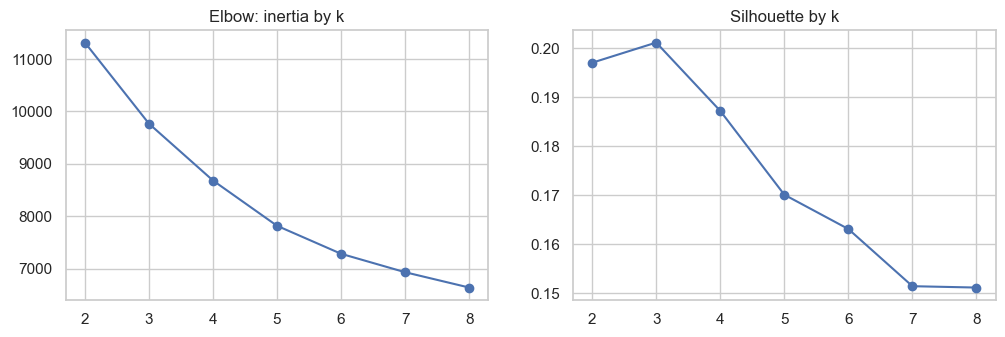

k,2,3,4,5,6,7,8
silhouette,0.197,0.201,0.187,0.170,0.163,0.151,0.151
stability_ARI,0.970,0.961,0.925,0.938,0.897,0.837,0.785


In [43]:
# choosing k: elbow (inertia) and silhouette
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(ks, inertia, marker='o'); ax[0].set_title('Elbow: inertia by k')
ax[1].plot(ks, sil, marker='o'); ax[1].set_title('Silhouette by k')
plt.show()

# stability of each k: refit on 10 random 80% samples, compare with the full fit (ARI, 1 = same clusters)
def stability(k, runs=10):
    full = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    rng = np.random.default_rng(0)
    scores = []
    for i in range(runs):
        idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
        scores.append(adjusted_rand_score(full, KMeans(n_clusters=k, n_init=10, random_state=i).fit(X[idx]).predict(X)))
    return np.mean(scores)

pd.DataFrame({'k': ks, 'silhouette': np.round(sil, 3), 'stability_ARI': [round(stability(k), 3) for k in ks]}).set_index('k').T

To choose k, I look at 3 things together:
- **Silhouette** (Rousseeuw, 1987): how well each seller fits its own cluster compared with the next one. Higher is better.
- **Elbow:** where adding clusters stops helping much.
- **Stability:** do the same clusters come back on random 80% samples (ARI; Hubert & Arabie, 1985)?

**k = 3 has the best silhouette (0.201) and is very stable (0.96).** k = 2 is slightly more stable but only splits big from small sellers, which is too coarse to act on. From k = 4 on, the silhouette falls. So I choose **k = 3**.

To be honest about it: a silhouette of 0.2 is low. Sellers form more of a **continuum** than sharply separated groups, so the segments are useful *partitions* for decisions, not natural types.

In [44]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
big['segment'] = km.labels_
print('silhouette k-means:', round(silhouette_score(X, big.segment), 3))

# profile of each segment (medians are easier to read than means here)
profile = big.groupby('segment')[features + ['n_orders', 'cancel_rate']].median().round(2)
profile['sellers'] = big.segment.value_counts()
profile['revenue_share'] = (big.groupby('segment').revenue.sum() / sel.revenue.sum()).round(3)

# name each segment from its profile, so the names don't depend on the random cluster number
# the biggest earner is 'core'; of the rest, the slowest is 'struggling'; the last one is 'small and fast'
core = profile.revenue_share.idxmax()
struggling = profile.drop(core).avg_delivery_days.idxmax()
names = {core: 'Core established', struggling: 'Struggling on service'}
names.update({s: 'Small, fast, well-rated' for s in profile.index if s not in names})
assert len(set(names.values())) == K, 'two segments got the same name, check the profiles'
big['segment_name'] = big.segment.map(names)
profile.index = profile.index.map(names)
big[['seller_id', 'segment_name']].to_csv('clean/seller_segments.csv', index=False)
profile

silhouette k-means: 0.201


,revenue,avg_price,active_months,n_categories,late_rate,avg_review,avg_delivery_days,freight_ratio,n_orders,cancel_rate,sellers,revenue_share
segment,,,,,,,,,,,,
Struggling on service,1686.52,104.67,6.9,1.5,0.17,3.62,16.62,0.20,11.0,0.0,286,0.069
"Small, fast, well-rated",848.30,59.07,4.2,2.0,0.00,4.36,9.19,0.29,10.0,0.0,711,0.067
Core established,6772.00,138.11,12.6,3.0,0.05,4.17,12.27,0.15,41.0,0.0,797,0.823


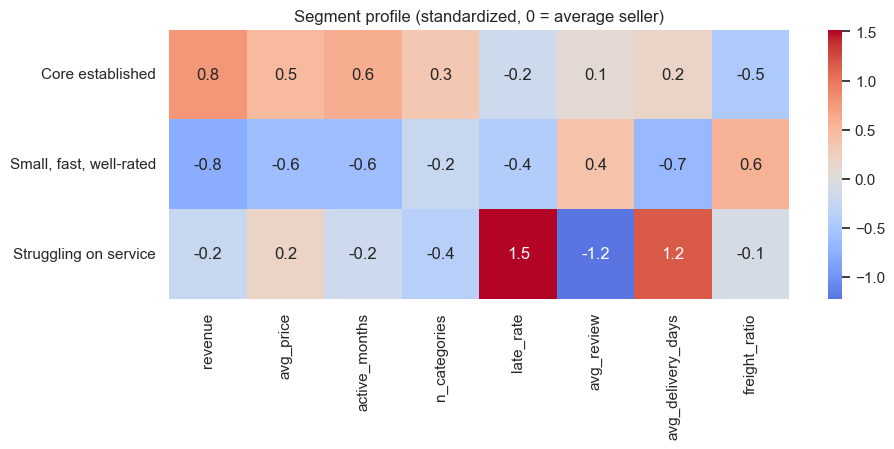

In [45]:
# heatmap of the standardized means, to see what makes each segment different
z = pd.DataFrame(X, columns=features).groupby(big.segment_name).mean()
plt.figure(figsize=(10, 3.5)); sns.heatmap(z, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Segment profile (standardized, 0 = average seller)'); plt.ylabel(''); plt.show()

**The 3 segments** (medians):

| Segment | Sellers | Revenue share | What stands out |
|---|---|---|---|
| **Core established** | 797 | **82%** | 41 orders, active 12.6 months, 3 categories, late 5%, review 4.17 |
| **Struggling on service** | 286 | 7% | **late 17%**, **review 3.62**, delivery 16.6 days |
| **Small, fast, well-rated** | 711 | 7% | cheap items (59 BRL), **fastest delivery (9.2 days)**, **best review (4.36)**, freight is 29% of the price |

The heatmap shows the same picture. The core sellers are high on every sales measure. The struggling ones are high on late rate and delivery days and low on review. The small fast ones are the opposite on service.

### 3.1 Robustness checks
Six checks: a fair comparison with the baseline, stability on resamples, a different clustering method, a different minimum-orders rule, what a 4th cluster adds, and at-risk sellers by rule.

In [46]:
# (0) a FAIR comparison with the baseline: which grouping better separates something it was NOT built on?
# outcome: is the seller still selling in the last two months of data (Jul-Aug 2018)?
big['still_selling'] = (big.last_sale >= '2018-07-01').astype(int)
def eta_squared(groups, y):
    # share of the variation in y explained by the groups (0 = none, 1 = all)
    return ((y.groupby(groups).transform('mean') - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print('still selling, explained by baseline tiers:', round(eta_squared(big.baseline, big.still_selling), 3),
      '| by k-means segments:', round(eta_squared(big.segment_name, big.still_selling), 3))
print(big.groupby('segment_name').still_selling.mean().round(2).to_dict())

# (a) stability: refit on 20 random 80% samples and compare with the main solution
rng = np.random.default_rng(42)
ari = []
for i in range(20):
    idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    km_b = KMeans(n_clusters=K, n_init=10, random_state=i).fit(X[idx])
    ari.append(adjusted_rand_score(big.segment, km_b.predict(X)))
print('bootstrap stability (ARI, 1 = identical): mean', round(np.mean(ari), 3), '| min', round(np.min(ari), 3))

# (b) a different method: Ward hierarchical clustering
ward = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X)
print('agreement k-means vs Ward (ARI):', round(adjusted_rand_score(big.segment, ward), 3))

# (c) does the minimum-orders rule change the segments?
for m in [3, 10]:
    sub = sel[sel.n_orders >= m].reset_index(drop=True)
    lab = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(make_X(sub))
    common = sub.seller_id.isin(big.seller_id)
    main = big.set_index('seller_id').segment.loc[sub.seller_id[common]].values
    print(f'min orders {m}: {len(sub)} sellers | ARI with main solution on common sellers:', round(adjusted_rand_score(main, lab[common]), 3))

# (d) what does k = 4 add?
big['segment_k4'] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X)
print(big.groupby('segment_k4')[['revenue', 'avg_review', 'late_rate', 'avg_delivery_days']].median().assign(sellers=big.segment_k4.value_counts()).round(2))

# (e) at-risk sellers by a simple rule, since cancellations are not in the clustering
at_risk = big[big.cancel_rate > 0.10]
print('at-risk sellers (cancel rate > 10%):', len(at_risk), '| median review', at_risk.avg_review.median().round(2),
      '| by segment:', at_risk.segment_name.value_counts().to_dict())

still selling, explained by baseline tiers: 0.031 | by k-means segments: 0.038
{'Core established': 0.73, 'Small, fast, well-rated': 0.68, 'Struggling on service': 0.46}
bootstrap stability (ARI, 1 = identical): mean 0.951 | min 0.902
agreement k-means vs Ward (ARI): 0.508
min orders 3: 2171 sellers | ARI with main solution on common sellers: 0.718
min orders 10: 1271 sellers | ARI with main solution on common sellers: 0.713
            revenue  avg_review  late_rate  avg_delivery_days  sellers
segment_k4                                                            
0            767.91        4.15       0.04              11.13      400
1           7140.47        4.16       0.05              12.43      728
2           1832.43        3.54       0.19              17.31      224
3           1082.34        4.43       0.00               8.18      442
at-risk sellers (cancel rate > 10%): 49 | median review 3.5 | by segment: {'Struggling on service': 24, 'Small, fast, well-rated': 18, 'Core esta

- **Fair comparison:** I test both groupings on something neither was built from, namely whether the seller was **still selling in Jul to Aug 2018**. K-means explains a little more of it than the baseline tiers (eta² 0.038 vs 0.031), so it's only **slightly** better on this outside test. The segments do differ in a useful way: 73% of core sellers and 68% of small fast sellers were still selling, but only **46% of struggling sellers**. Poor service goes together with sellers leaving, which supports acting on that group first. (`active_months` is partly related to this outcome, so the test isn't perfectly independent.)
- **Resampling:** mean ARI 0.95 (lowest 0.90), so the segments come back reliably.
- **Ward clustering** (Ward, 1963) agrees only moderately (ARI 0.51). The broad picture holds, but the exact borders depend on the method.
- **Minimum orders:** with 3 or 10, the ARI is about 0.71 to 0.72, so the segments change only moderately.
- **k = 4** splits the small fast group into a mid group and a very fast group (8 days). It adds no new kind of seller.
- **At-risk sellers by rule:** 49 sellers cancel more than 10% of orders (median review 3.5). They are spread across all 3 segments (24 struggling, 18 small, 7 core), which is why a separate rule is needed.

**Conclusion:** the 3 groups are stable and lead to different actions, but the outside test shows they explain only a little of seller retention. Segment membership should be refreshed regularly.

In [47]:
# sellers with fewer than 5 orders: described, not clustered
small = sel[sel.n_orders < MIN_ORDERS]
print('small sellers:', len(small), '| revenue share:', round(small.revenue.sum() / sel.revenue.sum(), 3))
print('median months active:', small.active_months.median(), '| sold in last 3 months of data:',
      (small.last_sale >= '2018-06-01').mean().round(2))
small[['n_orders', 'revenue', 'avg_review', 'late_rate', 'cancel_rate']].median().round(2)

small sellers: 1301 | revenue share: 0.041
median months active: 0.2 | sold in last 3 months of data: 0.4


n_orders         2.00
revenue        169.90
avg_review       4.33
late_rate        0.00
cancel_rate      0.00
dtype: float64

**Small sellers (fewer than 5 orders):** 1,301 sellers with only **4.1% of revenue**. Their median time between first and last sale is under a week, and **40% sold in the last 3 months** of the data. So many are **new joiners**, while others sold a couple of times and stopped. Their reviews look fine (median 4.33), but they rest on 1 to 4 orders.

### 3.2 How Olist can serve and keep each segment
| Segment | Goal | What Olist can do |
|---|---|---|
| **Core established** (82% of revenue) | Keep them | Dedicated account managers, volume-based commission tiers, early access to campaigns (e.g. Black Friday), and watch for any rise in late rate. Losing a few of these sellers costs a lot. |
| **Struggling on service** | Fix service, the biggest retention risk (only 46% still selling) | Coaching on dispatch time, help choosing carriers in slow regions, a simple dashboard of late rate and reviews, and listing visibility tied to improvement. Late orders get 1-2 star reviews (Task 1), which hurts Olist's brand, not just the seller. |
| **Small, fast, well-rated** | Help them grow | Featured placement and promotion, and help with freight (it's 29% of their price, which puts off buyers of cheap items). Shipping several items together would help too. |
| **Small / new sellers** | Onboard | A "first 90 days" programme, since many are new. |
| **At-risk sellers (cancel rate > 10%, 49 sellers)** | Review | Look into the reasons for cancellations, and warn or support before they hurt customers. |

These segments describe sellers. They don't prove which action works. Each action should be piloted and judged by seller retention and service changes over the following months.

# Task 4. Unusual orders for operational review
**Question.** Which orders look unusual enough that someone at Olist should check them, and why?

I treat "unusual" as **an order that departs from the normal process in a way that needs a person to act**: logistics, finance or data quality. I use 2 approaches that complement each other:
1. **Business rules.** They catch *known* problems and every flag is easy to explain.
2. **Isolation Forest** (Liu, Ting & Zhou, 2008). It isolates orders whose *combination* of values is rare, which can catch cases no single rule covers.

**Assumptions:** the rule thresholds below are business judgements, not facts, and I state them so they can be changed. The date the data was extracted isn't given, so I **assume "today" is the last purchase date, 17 Oct 2018**. The *stuck_in_transit* rule depends on this. There's no list of confirmed problem orders, so the results can't be scored against a known answer.

In [48]:
om = orders_master.copy()
# ASSUMPTION: the data was extracted soon after the last order, so 'now' = last purchase date (17 Oct 2018)
data_end = om.order_purchase_timestamp.max()
print('data end used as today:', data_end.date())

# rule-based checks; each one has a plain business reason
rules4 = pd.DataFrame({
    'impossible_dates': om.flag_carrier_before_approval | om.flag_delivered_before_carrier,
    'status_conflict': om.flag_status_conflict,
    'payment_mismatch': om.flag_payment_mismatch,
    'review_before_purchase': om.flag_review_before_purchase,
    'very_late': om.days_late >= 30,                                         # a month past the promised day
    'stuck_in_transit': (~om.is_delivered) & (~om.is_canceled)
                        & (om.order_estimated_delivery_date < data_end - pd.Timedelta(days=30)),
    'canceled_after_shipping': om.is_canceled & om.order_delivered_carrier_date.notna(),
    'freight_over_2x_price': om.freight_ratio > 2,
    'very_high_value': om.total_paid > om.total_paid.quantile(0.999),
})
summary4 = rules4.sum().sort_values(ascending=False).to_frame('orders')
summary4['share_%'] = (summary4.orders / len(om) * 100).round(2)
summary4

data end used as today: 2018-10-17


,orders,share_%
stuck_in_transit,1736,1.75
impossible_dates,1382,1.39
very_late,360,0.36
freight_over_2x_price,354,0.36
payment_mismatch,250,0.25
very_high_value,99,0.10
canceled_after_shipping,75,0.08
review_before_purchase,61,0.06
status_conflict,29,0.03


| Rule | Orders | Why it needs review | Who acts |
|---|---|---|---|
| stuck_in_transit | 1,736 | not delivered and not canceled, though the promised date passed more than 30 days before the end of the data. Probably lost, or the status was never updated | Logistics |
| impossible_dates | 1,382 | picked up before approval, or delivered before pickup | Data / IT |
| very_late | 360 | arrived 30 or more days after the promised day | Customer service |
| freight_over_2x_price | 354 | freight more than twice the item value | Pricing |
| payment_mismatch | 250 | paid amount differs from items + freight by more than 1 BRL | Finance |
| very_high_value | 99 | top 0.1% of order value | Fraud check |
| canceled_after_shipping | 75 | canceled after it was handed to the carrier | Returns |
| review_before_purchase | 61 | review dated before the order | Data / IT |
| status_conflict | 29 | status contradicts the dates | Data / IT |

I first set the freight rule at "freight above price", but that flagged 3,159 orders, mostly very cheap items where high freight is normal. **Twice the price** (354 orders) is a more useful level for a person to check.

In [49]:
from sklearn.ensemble import IsolationForest

# Isolation Forest looks for unusual COMBINATIONS of what was ordered and how it was paid.
# Delivery outcomes are left out (the 'very_late' rule already covers them), so every order with items
# can be scored, including canceled and stuck ones.
iso_cols = ['items_value', 'freight_value', 'freight_ratio', 'weight_g', 'distance_km', 'n_items', 'n_sellers',
            'estimated_days', 'max_installments', 'total_paid']
d = om[om.n_items.notna()].copy()
Xi = d[iso_cols].fillna(d[iso_cols].median())      # a few orders have missing weight or payment
for c in ['items_value', 'freight_value', 'freight_ratio', 'weight_g', 'distance_km', 'total_paid']:
    Xi[c] = np.log1p(Xi[c])
Xi = StandardScaler().fit_transform(Xi)

iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=42).fit(Xi)
d['iso_score'] = -iso.score_samples(Xi)          # higher = more unusual
d['iso_flag'] = iso.predict(Xi) == -1
print('orders scored:', len(d), '| flagged by Isolation Forest:', d.iso_flag.sum(),
      '| of which not delivered:', (~d.is_delivered[d.iso_flag]).sum())

# what do the flagged orders look like compared with normal ones?
d.groupby('iso_flag')[iso_cols].median().T.round(1)

orders scored: 98666 | flagged by Isolation Forest: 987 | of which not delivered: 28


iso_flag,False,True
items_value,85.0,415.9
freight_value,17.1,84.4
freight_ratio,0.2,0.2
weight_g,733.0,8550.0
distance_km,434.5,497.1
n_items,1.0,3.0
n_sellers,1.0,1.0
estimated_days,23.2,26.3
max_installments,2.0,6.0
total_paid,104.4,508.2


Isolation Forest uses only what was ordered and how it was paid. I left out delivery outcomes, because the *very_late* rule already covers them, and this lets it score **every order with items, including canceled and stuck ones**. It flagged 987 orders (I set it to the top 1%), of which 28 were not delivered. Compared with normal orders, they are **big, heavy, multi-item purchases**: median 416 BRL vs 85, 8.6 kg vs 0.7 kg, 3 items vs 1, paid in 6 installments vs 2. These are unusual, but **mostly legitimate**. They're most relevant for a fraud or high-value check.

In [50]:
# robustness: (a) same orders with different random seeds?  (b) overlap with the rules
top_sets = []
for seed in [0, 1, 2]:
    s = -IsolationForest(n_estimators=300, random_state=seed).fit(Xi).score_samples(Xi)
    top_sets.append(set(d.order_id[s >= np.quantile(s, 0.99)]))
base = set(d.order_id[d.iso_flag])
print('overlap of top 1% across seeds (Jaccard):', [round(len(base & t) / len(base | t), 2) for t in top_sets])

any_rule = rules4.loc[d.index].any(axis=1)
print('Isolation Forest flags that ALSO break a rule:', round(any_rule[d.iso_flag].mean(), 3),
      '| rule breakers among normal orders:', round(any_rule[~d.iso_flag].mean(), 3))

overlap of top 1% across seeds (Jaccard): [0.78, 0.78, 0.76]
Isolation Forest flags that ALSO break a rule: 0.108 | rule breakers among normal orders: 0.042


- **Different random seeds:** the top 1% overlaps by 76 to 78% (Jaccard), so the core of the list is stable and the edges change.
- **Agreement with the rules:** 10.8% of Isolation Forest flags also break a rule, compared with 4.2% of other orders. That's about 2.6 times more, so the method picks up related cases. Still, most of its flags aren't errors, which supports keeping the rules as the main tool.
- The 1% contamination is an assumption. A different value would change how long the list is, not which orders come first.

In [51]:
# final review list: an order goes in if it breaks a rule or is flagged by Isolation Forest
review = om[['order_id', 'order_status', 'order_purchase_timestamp', 'customer_state', 'total_paid', 'days_late']].copy()
review['reasons'] = rules4.apply(lambda r: ', '.join(r.index[r]), axis=1)
review['iso_flag'] = False
review.loc[d.index, 'iso_flag'] = d.iso_flag
review.loc[review.iso_flag, 'reasons'] = (review.reasons + ', unusual_combination').str.strip(', ')
review['n_reasons'] = rules4.sum(axis=1) + review.iso_flag
# a customer may still be waiting on these, so they go first among orders with the same number of reasons
review['customer_waiting'] = rules4.stuck_in_transit | rules4.very_late
review = review[review.n_reasons > 0].sort_values(['n_reasons', 'customer_waiting', 'total_paid'], ascending=False)
review.to_csv('clean/orders_for_review.csv', index=False)
review.head(500).to_csv('clean/orders_for_review_top500.csv', index=False)   # a list one team can handle
print('orders for review:', len(review), f'({len(review) / len(om):.1%} of all orders)')
print(review.n_reasons.value_counts().sort_index())
review.head(10)

orders for review: 5164 (5.2% of all orders)
n_reasons
1    4996
2     167
3       1
Name: count, dtype: int64


,order_id,order_status,order_purchase_timestamp,customer_state,total_paid,days_late,reasons,iso_flag,n_reasons,customer_waiting
70079,83167649ca3fb63d1a7daada42232e14,processing,2017-04-06 17:11:06,SP,2566.90,NaN,"stuck_in_transit, very_high_value, unusual_com...",True,3,True
62768,ab13cb6c13063f2603a94c9ddca34f66,invoiced,2018-01-16 20:18:10,MT,1724.04,NaN,"stuck_in_transit, unusual_combination",True,2,True
54206,466839bc7437c08a787345cd313ba3dd,invoiced,2018-01-19 15:18:41,RS,1711.63,NaN,"stuck_in_transit, unusual_combination",True,2,True
24067,1c9fd2a0749771fdb8c1cad52a3c27a6,invoiced,2018-01-21 19:44:46,SC,1683.14,NaN,"stuck_in_transit, unusual_combination",True,2,True
33590,1c49e3fd28c9c369b12fd84446e475ab,processing,2017-04-06 07:04:06,SP,1682.92,NaN,"stuck_in_transit, unusual_combination",True,2,True
97847,b73bbac6285251dbf2dd01842e0ce0de,delivered,2018-01-10 13:10:09,RJ,1642.54,33.0,"very_late, unusual_combination",True,2,True
16239,2cc53a4aa9a5a0f2c0ff6559260fb1d4,processing,2017-08-06 20:49:26,SP,1356.80,NaN,"stuck_in_transit, unusual_combination",True,2,True
74966,a6a5d5673d42186a8b8b94ad29b59897,delivered,2017-05-15 00:45:02,SP,1247.36,31.0,"very_late, unusual_combination",True,2,True
58317,0689012a897b2ac50b37994d77898bc8,processing,2017-03-08 10:44:37,PR,1097.31,NaN,"stuck_in_transit, unusual_combination",True,2,True
72730,e81600d4371046078150ab84d31175d3,shipped,2017-01-25 09:31:09,PA,986.32,NaN,"stuck_in_transit, unusual_combination",True,2,True


The full list has **5,164 orders (5.2%)**. That's more than one team can check, so I also save a **shortlist of the top 500**. The order is: number of reasons, then **whether a customer may still be waiting** (stuck in transit or very late), then value. 167 orders break 2 rules and 1 breaks 3. The top of the list is mostly **high-value orders stuck in processing or invoiced** for months, which is exactly where a customer is most likely still waiting for money or goods.

Files: `clean/orders_for_review.csv` (all) and `clean/orders_for_review_top500.csv` (shortlist).

**Recommendation:** route each order by its reason (table above). Because nothing is labelled, I suggest the teams check a random sample of about 100 flagged orders, to measure how many are real problems and adjust the thresholds.

# Task 5. Predicting late delivery and delivery days
**Two questions, two models**
1. **Will this order arrive late?** (classification: `is_late`)
2. **How many days will it take from purchase to delivery?** (regression: `delivery_days`)

**Key rule: no leakage.** Only information known **at the moment the order is placed** is used: value, freight, weight, size, distance, seller and customer state, category, payment, time of purchase, and Olist's own estimated delivery time (shown to the customer at checkout). Carrier and delivery dates, the review and approval time are **not** used, because they happen after purchase.

**Other assumptions:** only delivered orders, partial months removed. For orders with several items, seller state and category come from the first item. This is a simplification, but 97% of orders have one seller.

**Models:**
- **Logistic / linear regression:** simple, transparent baselines.
- **Gradient boosting** (Friedman, 2001; scikit-learn's HistGradientBoosting): captures non-linear effects and interactions, such as distance mattering more in some states.

**Metrics:**
- **Late:** about 7% of orders are late, so accuracy would be misleading. I use ROC-AUC and PR-AUC (Saito & Rehmsmeier, 2015).
- **Days:** MAE, the average error in days, which is easy to explain to managers, plus RMSE and R².

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.base import clone   # each model gets its OWN copy of the preprocessing step
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error, root_mean_squared_error, r2_score

# seller state and main category of each order (taken from its first item)
first_item = items.sort_values('order_item_id').drop_duplicates('order_id')[['order_id', 'seller_state', 'category']]
m5 = orders_master[orders_master.is_delivered & ~orders_master.partial_month].merge(first_item, on='order_id', how='left')
m5['same_state'] = (m5.seller_state == m5.customer_state).astype(int)
m5['purchase_month_num'] = m5.order_purchase_timestamp.dt.month

# ONLY information known when the order is placed (no carrier or delivery dates, no review)
num_cols = ['items_value', 'freight_value', 'n_items', 'n_sellers', 'weight_g', 'volume_cm3', 'distance_km',
            'estimated_days', 'max_installments', 'same_state', 'purchase_weekday', 'purchase_hour', 'purchase_month_num']
cat_cols = ['customer_state', 'seller_state', 'category', 'main_payment_type']
m5 = m5.dropna(subset=num_cols + ['delivery_days'])

# time split: learn from the past, test on the most recent months
train = m5[m5.order_purchase_timestamp < '2018-06-01']
test = m5[m5.order_purchase_timestamp >= '2018-06-01']
print('train:', len(train), train.order_purchase_timestamp.min().date(), 'to', train.order_purchase_timestamp.max().date(),
      '| late', f'{train.is_late.mean():.1%}')
print('test :', len(test), test.order_purchase_timestamp.min().date(), 'to', test.order_purchase_timestamp.max().date(),
      '| late', f'{test.is_late.mean():.1%}')

train: 77584 2017-01-05 to 2018-05-31 | late 7.6%
test : 18597 2018-06-01 to 2018-08-29 | late 3.6%


I split by **time**, not at random. The models learn from Jan 2017 to May 2018 (77,600 orders) and are tested on Jun to Aug 2018 (18,603 orders). That's how the model would really be used, predicting the future from the past.

Notice that the late rate **halves** from 7.6% in training to 3.6% in the test period. Delivery performance changes over time, which makes the test harder but also more realistic.

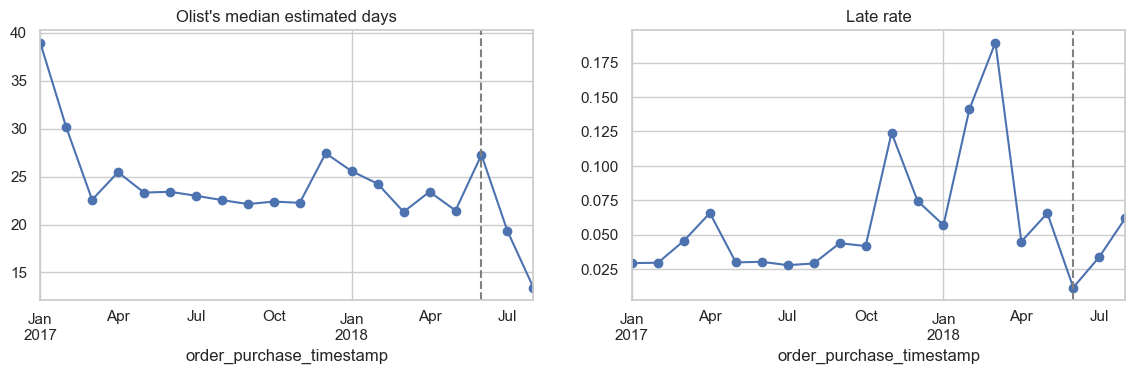

order_purchase_timestamp,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
median_estimate,25.570,24.260,21.324,23.420,21.465,27.278,19.333,13.433
late_rate,0.057,0.141,0.190,0.045,0.066,0.012,0.034,0.062


In [53]:
# drift check: Olist's own estimate (our strongest feature) and the late rate, month by month
monthly5 = m5.groupby(m5.order_purchase_timestamp.dt.to_period('M')).agg(
    median_estimate=('estimated_days', 'median'), late_rate=('is_late', 'mean'))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
monthly5.median_estimate.plot(ax=ax[0], marker='o', title="Olist's median estimated days")
monthly5.late_rate.plot(ax=ax[1], marker='o', title='Late rate')
for a in ax: a.axvline(pd.Period('2018-06', 'M'), color='grey', ls='--')   # start of the test period
plt.show()
monthly5.loc['2018-01':].round(3).T

**Drift check.** The feature the model relies on most, Olist's estimated days, **changes in the test period**. The median estimate was 21 to 26 days from Jan to May 2018, then 27 in June, 19 in July and **13 in August**. The late rate moves with it: very low in June (1.2%), rising to 6.2% in August as the estimates get shorter. So the model is tested under a different estimating policy from the one it learned. This is the main reason to retrain often, and it partly explains why the late model is only moderately accurate.

In [54]:
prep = ColumnTransformer([('num', StandardScaler(), num_cols),
                          ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), cat_cols)])
y_tr, y_te = train.is_late.astype(int), test.is_late.astype(int)

clf_models = {
    'Logistic regression': make_pipeline(clone(prep), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Gradient boosting': make_pipeline(clone(prep), HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42)),
}
res, proba = [], {}
res.append({'model': 'Baseline (no skill)', 'ROC-AUC': 0.5, 'PR-AUC': y_te.mean()})
for name, model in clf_models.items():
    model.fit(train[num_cols + cat_cols], y_tr)
    p = model.predict_proba(test[num_cols + cat_cols])[:, 1]
    proba[name] = p
    res.append({'model': name, 'ROC-AUC': roc_auc_score(y_te, p), 'PR-AUC': average_precision_score(y_te, p)})
pd.DataFrame(res).round(3)

,model,ROC-AUC,PR-AUC
0,Baseline (no skill),0.500,0.036
1,Logistic regression,0.696,0.077
2,Gradient boosting,0.713,0.079


In [55]:
# in practice Olist could only check a few orders, so: if we flag the riskiest 10%, how many late orders do we catch?
p = proba['Gradient boosting']
flag = p >= np.quantile(p, 0.90)
print(f'flag top 10% -> precision {y_te[flag].mean():.1%} (vs {y_te.mean():.1%} late overall), '
      f'recall {y_te[flag].sum() / y_te.sum():.1%} of all late orders')

flag top 10% -> precision 8.7% (vs 3.6% late overall), recall 24.0% of all late orders


Both models beat the no-skill baseline. Gradient boosting has **ROC-AUC 0.71** (logistic 0.70). PR-AUC is **0.081 vs 0.036** for random guessing, about 2.2 times better.

In practical terms, if Olist checks the **riskiest 10%** of orders, **8.9% of them are late** compared with 3.6% overall (2.5 times higher), and that 10% contains **25% of all late orders**. The 10% is a business capacity choice. It wasn't tuned on the test set.

That's **modest**. Lateness depends mostly on what happens *after* the purchase (carrier delays, weather, strikes), which we can't see at checkout. So the model is useful for **ranking risk**, not for a confident yes/no.

In [56]:
# delivery days (regression)
yd_tr, yd_te = train.delivery_days, test.delivery_days
reg = []
reg.append({'model': 'Baseline: median of train', 'pred': np.full(len(test), yd_tr.median())})
reg.append({'model': "Baseline: Olist's own estimate", 'pred': test.estimated_days.values})
lin = make_pipeline(clone(prep), LinearRegression()).fit(train[num_cols + cat_cols], yd_tr)
reg.append({'model': 'Linear regression', 'pred': lin.predict(test[num_cols + cat_cols])})
gbr = make_pipeline(clone(prep), HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, loss='absolute_error', random_state=42))
gbr.fit(train[num_cols + cat_cols], yd_tr)
reg.append({'model': 'Gradient boosting', 'pred': gbr.predict(test[num_cols + cat_cols])})
pd.DataFrame([{'model': r['model'], 'MAE (days)': mean_absolute_error(yd_te, r['pred']),
               'RMSE (days)': root_mean_squared_error(yd_te, r['pred']), 'R2': r2_score(yd_te, r['pred'])} for r in reg]).round(2)

,model,MAE (days),RMSE (days),R2
0,Baseline: median of train,4.95,6.35,-0.19
1,Baseline: Olist's own estimate,12.72,15.43,-6.02
2,Linear regression,5.09,6.52,-0.25
3,Gradient boosting,3.42,5.06,0.24


Gradient boosting predicts delivery days with an **average error of 3.4 days** (R² 0.25). The simple median guess is off by 4.95 days, so the model is about 31% better. Linear regression does *worse* than the median, because the target is skewed with a long tail and its relationships aren't straight lines.

Olist's own estimate is off by 12.7 days on average. That's **not a fair accuracy comparison**, because Olist deliberately pads its estimate so that orders arrive "early". It does show that a model could give customers a much tighter and more realistic date.

### 5.1 Robustness checks
Three checks: different test periods, which features drive the predictions, and where the errors are largest.

In [57]:
# (a) rolling time windows: train on everything before, test on the next 2 months
roll = []
for start, end in [('2018-02-01', '2018-04-01'), ('2018-04-01', '2018-06-01'), ('2018-06-01', '2018-08-01')]:
    tr = m5[m5.order_purchase_timestamp < start]
    te = m5[(m5.order_purchase_timestamp >= start) & (m5.order_purchase_timestamp < end)]
    c = make_pipeline(clone(prep), HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42)).fit(tr[num_cols + cat_cols], tr.is_late.astype(int))
    r = make_pipeline(clone(prep), HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, loss='absolute_error', random_state=42)).fit(tr[num_cols + cat_cols], tr.delivery_days)
    roll.append({'test window': f'{start[:7]} to {end[:7]}', 'late rate': te.is_late.mean(),
                 'ROC-AUC': roc_auc_score(te.is_late.astype(int), c.predict_proba(te[num_cols + cat_cols])[:, 1]),
                 'MAE model': mean_absolute_error(te.delivery_days, r.predict(te[num_cols + cat_cols])),
                 'MAE Olist estimate': mean_absolute_error(te.delivery_days, te.estimated_days)})
pd.DataFrame(roll).round(3)

,test window,late rate,ROC-AUC,MAE model,MAE Olist estimate
0,2018-02 to 2018-04,0.166,0.673,7.525,10.569
1,2018-04 to 2018-06,0.055,0.662,4.337,12.857
2,2018-06 to 2018-08,0.023,0.745,3.674,15.093


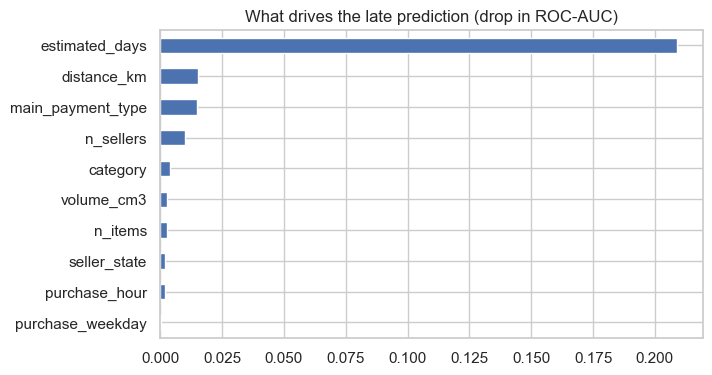

estimated_days       0.2089
distance_km          0.0153
main_payment_type    0.0148
n_sellers            0.0100
category             0.0040
volume_cm3           0.0028
dtype: float64

In [58]:
# (b) which features matter? permutation importance on a sample of the test set
from sklearn.inspection import permutation_importance
smp = test.sample(5000, random_state=42)
pi = permutation_importance(clf_models['Gradient boosting'], smp[num_cols + cat_cols], smp.is_late.astype(int),
                            scoring='roc_auc', n_repeats=3, random_state=42)
imp = pd.Series(pi.importances_mean, index=num_cols + cat_cols).sort_values()
imp.tail(10).plot.barh(figsize=(7, 4), title='What drives the late prediction (drop in ROC-AUC)'); plt.show()
imp.sort_values(ascending=False).head(6).round(4)

In [59]:
# (c) where are the errors biggest? MAE by customer state (states with 300+ test orders)
err = test.assign(abs_err=np.abs(yd_te - reg[3]['pred']))
by_state = err.groupby('customer_state').agg(orders=('order_id', 'size'), MAE=('abs_err', 'mean'), late_rate=('is_late', 'mean'))
by_state[by_state.orders >= 300].sort_values('MAE').round(2)

,orders,MAE,late_rate
customer_state,,,
SP,8610,2.56,0.05
PR,947,3.14,0.02
GO,332,3.32,0.03
MG,2058,3.38,0.01
SC,600,3.56,0.02
ES,348,3.75,0.04
DF,455,3.77,0.03
RS,904,3.81,0.02
RJ,2126,4.38,0.03


- **Rolling time windows:** ROC-AUC stays between **0.66 and 0.74**, and the day model has a smaller error than Olist's estimate in every window. Olist pads its estimate on purpose, so this shows a tighter *realistic* date is possible, not that Olist's estimate is "wrong". The **Feb to Apr 2018** window had an unusually high late rate (**16.6%**), and that's where the model did worst (MAE 7.5 days). The model can't foresee disruptions that affect the whole delivery network.
- **Feature importance** (permutation, on the test set): **Olist's estimated days** matters far more than anything else. A shorter promised window means a higher chance of being late (Task 1 found a correlation of -0.50 between estimated days and days late). Payment type, number of sellers and distance follow, a long way behind.
- **Errors by state:** smallest in SP (2.6 days) and the south and southeast, largest in the **northeast (BA 6.0, PE 6.2 days)**. This matches the distance and region pattern from Task 1.

### 5.2 Limitations and use
- **Drift:** the estimating policy and the late rate change from month to month (see the drift check), so the models should be **retrained regularly** (for example monthly) and monitored.
- **No tuning:** model settings are fixed sensible defaults, with no separate validation set. This keeps the test period untouched and avoids overfitting it, at the cost of possibly leaving some accuracy unused.
- **How to use them:** the late model as a **risk score** (send a proactive message, pick a faster carrier for high-risk orders), not as a promise. The days model could give a more realistic delivery date with a safety margin.
- **Responsible use:** errors are larger for northeast customers. The model shouldn't be used to give these customers worse service or longer promised dates without checking that this is fair. No personal data besides state was used.
- **Simplification:** for orders with several sellers, only the first item's seller and category are used.

## Headline numbers
The comments above quote numbers by hand. This cell recomputes the main ones, so a reader can check that the text still matches the data after any change.

In [60]:
pd.Series({
    'late rate, delivered orders (%)': round(orders_master.loc[orders_master.is_delivered, 'is_late'].mean() * 100, 1),
    'orders with 2+ categories': int((cats_per_order > 1).sum()),
    'significant customer-level rules': len(strong_cust),
    'sellers clustered': len(big),
    'k-means silhouette': round(silhouette_score(X, big.segment), 3),
    'orders for review': len(review),
    'late model ROC-AUC (gradient boosting)': round(roc_auc_score(y_te, proba['Gradient boosting']), 3),
    'delivery days MAE (gradient boosting)': round(mean_absolute_error(yd_te, reg[3]['pred']), 2),
}).to_frame('value')

,value
"late rate, delivered orders (%)",6.800
orders with 2+ categories,727.000
significant customer-level rules,5.000
sellers clustered,1794.000
k-means silhouette,0.201
orders for review,5164.000
late model ROC-AUC (gradient boosting),0.713
delivery days MAE (gradient boosting),3.420


# References
- Agrawal, R., Imieliński, T., & Swami, A. (1993). Mining association rules between sets of items in large databases. *ACM SIGMOD Record, 22*(2), 207–216. https://doi.org/10.1145/170036.170072
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x
- Brin, S., Motwani, R., Ullman, J. D., & Tsur, S. (1997). Dynamic itemset counting and implication rules for market basket data. In *Proceedings of the 1997 ACM SIGMOD International Conference on Management of Data* (pp. 255–264). https://doi.org/10.1145/253260.253325
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation forest. In *2008 Eighth IEEE International Conference on Data Mining* (pp. 413–422). https://doi.org/10.1109/ICDM.2008.17
- Olist. (2018). *Brazilian e-commerce public dataset by Olist* (Version 2) [Data set]. Kaggle. https://doi.org/10.34740/kaggle/dsv/195341
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845